# Bài 4: K láng giềng gần nhất
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Notebook này làm lại toàn bộ bài thực hành `Lab04_KNN.pdf` trên ba bộ dữ liệu:

- `sinh_vien_mo_rong.csv` — 120 sinh viên quen thuộc của bài 2, có thêm cột **chi tiêu hàng tháng**.
- `hai_vang_trang.csv` — 300 điểm chia đều hai lớp, nằm trên hai vầng trăng khuyết lồng vào nhau
  (ranh giới **cong**).
- `gia_nha.csv` — 60 căn hộ của bài 1, dùng cho KNN hồi quy.

| Phần | Nội dung | Tương ứng trong tài liệu |
|---|---|---|
| A | 5 bước của bài thực hành | Mục 2 → Mục 6 (`e1` … `e5`) |
| B | 6 bài tập nộp | Mục 7 |

Ba buổi trước, mọi mô hình đều rút dữ liệu huấn luyện thành vài con số rồi bỏ dữ liệu đi. Buổi này
làm ngược lại: mô hình **giữ nguyên toàn bộ dữ liệu**, gặp mẫu mới thì đi hỏi những mẫu cũ giống nó nhất.

**Cách dùng:** chạy lần lượt từ trên xuống (`Shift + Enter`). Mỗi bước đều in ra con số để đối chiếu
với tài liệu. Mọi hình vẽ đều được lưu thêm một bản vào thư mục `images/` cạnh notebook.

**Thư viện cần có:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`.

```
pip install numpy pandas matplotlib scikit-learn
```

## 0. Chuẩn bị môi trường

Tài liệu quy ước dữ liệu nằm trong thư mục `data/`; nếu notebook đặt cạnh các tệp CSV thì đường dẫn
chỉ là tên tệp. Hàm `tim_tep` tự dò cả hai chỗ. Hàm `luu_hinh` lưu hình vào `images/` **trước** khi
`plt.show()` đóng hình lại.

In [1]:
# -*- coding: utf-8 -*-
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def tim_tep(ten_tep):
    """Ưu tiên bố cục data/ của tài liệu, nếu không có thì lấy tệp cùng thư mục."""
    for duong_dan in (Path("data") / ten_tep, Path(ten_tep)):
        if duong_dan.exists():
            return duong_dan
    raise FileNotFoundError(
        f"Khong tim thay {ten_tep}. Hay dat notebook canh tep CSV, "
        "hoac tao thu muc data/ va bo tep vao do."
    )


DUONG_DAN_SV = tim_tep("sinh_vien_mo_rong.csv")
DUONG_DAN_TRANG = tim_tep("hai_vang_trang.csv")
DUONG_DAN_NHA = tim_tep("gia_nha.csv")
for ten, duong_dan in [("sinh vien", DUONG_DAN_SV), ("hai vang trang", DUONG_DAN_TRANG),
                       ("gia nha", DUONG_DAN_NHA)]:
    print(f"Doc {ten:15s} tu: {duong_dan.resolve()}")

# Mọi hình vẽ được lưu thêm một bản vào images/ cạnh notebook.
THU_MUC_ANH = Path("images")
THU_MUC_ANH.mkdir(exist_ok=True)


def luu_hinh(ten_tep):
    """Lưu hình đang vẽ vào images/ rồi mới hiện ra màn hình."""
    plt.savefig(THU_MUC_ANH / ten_tep, dpi=150, bbox_inches="tight")
    plt.show()


# DejaVu Sans (phông mặc định của matplotlib) có đủ dấu tiếng Việt nên hình vẽ hiện đúng chữ.
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Màu dùng xuyên suốt bài: xanh đậm cho lớp 1, đỏ cho lớp 0.
MAU_1 = "#1a365d"
MAU_0 = "#c53030"
NEN_1 = "#c3dafe"
NEN_0 = "#fed7d7"


def ve_bien(ax, mo_hinh, X, y, ten_cot=("x1", "x2"), so_diem=250, le=0.3):
    """Tô vùng dự đoán của một mô hình hai đặc trưng rồi chấm dữ liệu lên trên."""
    x_min, x_max = X[ten_cot[0]].min() - le, X[ten_cot[0]].max() + le
    y_min, y_max = X[ten_cot[1]].min() - le, X[ten_cot[1]].max() + le
    luoi_a, luoi_b = np.meshgrid(np.linspace(x_min, x_max, so_diem), np.linspace(y_min, y_max, so_diem))
    luoi = pd.DataFrame({ten_cot[0]: luoi_a.ravel(), ten_cot[1]: luoi_b.ravel()})
    vung = mo_hinh.predict(luoi).reshape(luoi_a.shape)
    ax.contourf(luoi_a, luoi_b, vung, levels=[-0.5, 0.5, 1.5], colors=[NEN_0, NEN_1], alpha=0.9)
    ax.scatter(X.loc[y == 1, ten_cot[0]], X.loc[y == 1, ten_cot[1]], s=14, marker="o",
               color=MAU_1, edgecolor="white", linewidth=0.4)
    ax.scatter(X.loc[y == 0, ten_cot[0]], X.loc[y == 0, ten_cot[1]], s=16, marker="^",
               color=MAU_0, edgecolor="white", linewidth=0.4)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

Doc sinh vien       tu: D:\HOC\HMUD\TH\04. KNN\sinh_vien_mo_rong.csv
Doc hai vang trang  tu: D:\HOC\HMUD\TH\04. KNN\hai_vang_trang.csv
Doc gia nha         tu: D:\HOC\HMUD\TH\04. KNN\gia_nha.csv


---
# Phần A — Bài thực hành

## Bước 1 — Khoảng cách và láng giềng *(Mục 2, `e1_khoang_cach.py`)*

### Ý tưởng

Muốn đoán một bạn mới có qua môn không, ta tìm những bạn cũ giống bạn ấy nhất rồi xem đa số các bạn
đó qua hay rớt. Đó là toàn bộ ý tưởng của **K láng giềng gần nhất** (*k-nearest neighbors*), viết tắt KNN.

Thuật toán gồm ba bước:

1. Tính khoảng cách từ mẫu mới tới **mọi** mẫu cũ.
2. Chọn ra $k$ mẫu gần nhất.
3. Cho $k$ mẫu đó bỏ phiếu, lớp nào nhiều phiếu hơn thì thắng.

> **KNN không học gì cả.** Bước huấn luyện của KNN chỉ là cất dữ liệu vào bộ nhớ, mọi phép tính dồn
> hết sang lúc dự đoán. Vì vậy người ta gọi KNN là mô hình **học lười** (*lazy learning*): huấn luyện
> tức thì nhưng dự đoán chậm, và dữ liệu càng lớn dự đoán càng chậm (Bài tập 6 sẽ đo).

### Khoảng cách Euclid

$$d(\boldsymbol{x}, \boldsymbol{z}) = \sqrt{(x_1 - z_1)^2 + (x_2 - z_2)^2 + \dots + (x_d - z_d)^2}$$

Đây chính là định lý Pitago mở rộng cho nhiều chiều. Ví dụ bạn P ôn 10 giờ, điểm giữa kỳ 5, còn bạn Q
ôn 13 giờ, điểm giữa kỳ 9. Khi đó $d(P, Q) = \sqrt{3^2 + 4^2} = 5$.

In [2]:
"""Bước 1: tự tính khoảng cách và tự tìm láng giềng, chưa dùng thư viện."""

# Ba bạn: A và C học gần như y hệt nhau, B học khác hẳn
ba_ban = {
    "A": np.array([5.0, 3.0, 4000.0]),
    "B": np.array([25.0, 9.0, 4100.0]),
    "C": np.array([6.0, 3.5, 7000.0]),
}


def kc(u, v):
    """Khoang cach Euclid giua hai diem."""
    return np.sqrt(((u - v) ** 2).sum())


print("Khoang cach KHI CHUA chuan hoa")
print(f"  d(A, B) = {kc(ba_ban['A'], ba_ban['B']):8.1f}")
print(f"  d(A, C) = {kc(ba_ban['A'], ba_ban['C']):8.1f}")
print()

# Chuẩn hoá bằng trung bình và độ lệch chuẩn của cả bộ dữ liệu
df = pd.read_csv(DUONG_DAN_SV)
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]].to_numpy(dtype=float)
tb = X.mean(axis=0)
dl = X.std(axis=0)
print("Do lech chuan cua ba cot:")
print(f"  gio_on {dl[0]:.2f}   diem_giua_ky {dl[1]:.2f}"
      f"   chi_tieu {dl[2]:.0f}")
print()

chuan = {ten: (v - tb) / dl for ten, v in ba_ban.items()}
print("Khoang cach SAU KHI chuan hoa")
print(f"  d(A, B) = {kc(chuan['A'], chuan['B']):.2f}")
print(f"  d(A, C) = {kc(chuan['A'], chuan['C']):.2f}")
print()

# Tìm 5 láng giềng gần nhất của một bạn mới, chỉ dùng hai cột học tập
X2 = df[["gio_on", "diem_giua_ky"]].to_numpy(dtype=float)
y = df["qua_mon"].to_numpy()
tb2, dl2 = X2.mean(axis=0), X2.std(axis=0)
ban_moi = np.array([12.0, 6.5])
X2c = (X2 - tb2) / dl2
moi_c = (ban_moi - tb2) / dl2
khoang = np.sqrt(((X2c - moi_c) ** 2).sum(axis=1))
gan = np.argsort(khoang)[:5]

print("Ban moi: on 12 gio, diem giua ky 6.5")
print("Nam lang gieng gan nhat:")
for i in gan:
    ket = "qua" if y[i] == 1 else "rot"
    print(f"  gio {X2[i, 0]:5.1f}  diem {X2[i, 1]:4.1f}  "
          f"khoang cach {khoang[i]:.3f}  -> {ket}")
so_qua = int(y[gan].sum())
print(f"Bo phieu: {so_qua} qua, {5 - so_qua} rot")
print("Du doan:", "qua mon" if so_qua >= 3 else "rot mon")

Khoang cach KHI CHUA chuan hoa
  d(A, B) =    102.2
  d(A, C) =   3000.0

Do lech chuan cua ba cot:
  gio_on 7.82   diem_giua_ky 2.09   chi_tieu 1692

Khoang cach SAU KHI chuan hoa
  d(A, B) = 3.85
  d(A, C) = 1.79

Ban moi: on 12 gio, diem giua ky 6.5
Nam lang gieng gan nhat:
  gio  10.5  diem  6.4  khoang cach 0.198  -> qua
  gio  12.5  diem  6.1  khoang cach 0.202  -> qua
  gio  14.0  diem  6.4  khoang cach 0.260  -> qua
  gio   9.5  diem  6.1  khoang cach 0.373  -> rot
  gio  10.5  diem  5.8  khoang cach 0.386  -> qua
Bo phieu: 4 qua, 1 rot
Du doan: qua mon


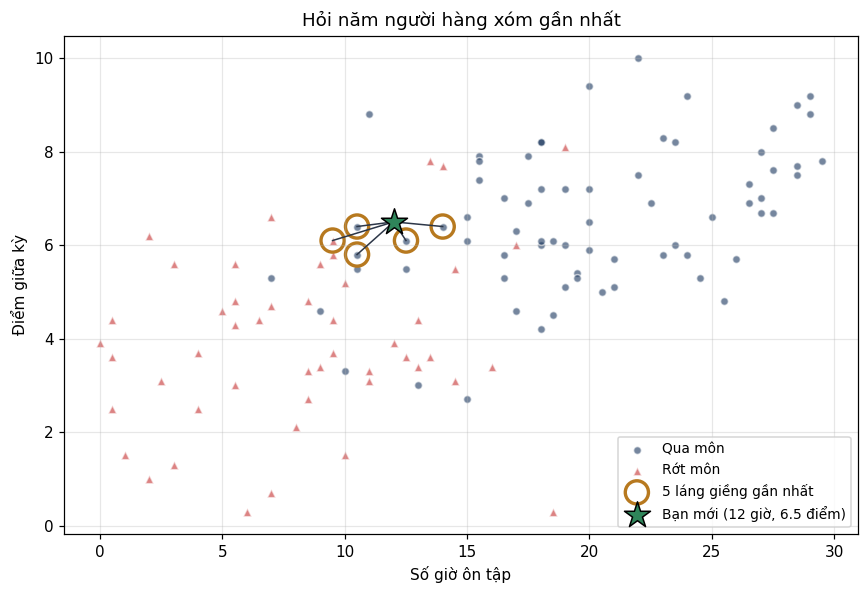

In [3]:
# Hình 1: hỏi năm người hàng xóm gần nhất
plt.figure(figsize=(8, 5.5))
plt.scatter(X2[y == 1, 0], X2[y == 1, 1], s=26, color=MAU_1, alpha=0.6, edgecolor="white", label="Qua môn")
plt.scatter(X2[y == 0, 0], X2[y == 0, 1], s=30, marker="^", color=MAU_0, alpha=0.6,
            edgecolor="white", label="Rớt môn")
for i in gan:
    plt.plot([ban_moi[0], X2[i, 0]], [ban_moi[1], X2[i, 1]], color="#2d3748", linewidth=1)
plt.scatter(X2[gan, 0], X2[gan, 1], s=230, facecolor="none", edgecolor="#b7791f", linewidth=2.2,
            label="5 láng giềng gần nhất")
plt.scatter([ban_moi[0]], [ban_moi[1]], s=320, marker="*", color="#2f855a", edgecolor="black",
            zorder=5, label="Bạn mới (12 giờ, 6.5 điểm)")
plt.xlabel("Số giờ ôn tập")
plt.ylabel("Điểm giữa kỳ")
plt.title("Hỏi năm người hàng xóm gần nhất")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
luu_hinh("hinh1_nam_lang_gieng_gan_nhat.png")

**Đọc kết quả:** phần cuối tìm được năm láng giềng của bạn mới, gồm **4 bạn qua và 1 bạn rớt**, nên mô
hình đoán bạn mới qua môn. Khoảng cách ở đây được tính **sau khi chuẩn hoá** (Bước 2 sẽ giải thích vì sao
bắt buộc phải làm vậy). Trên hình vẽ theo thang gốc, năm vòng tròn không hẳn là năm chấm "gần nhất bằng
mắt", vì một giờ ôn và một điểm giữa kỳ không cùng độ dài trên thang chuẩn hoá.

Phần đầu mới là chỗ đáng suy nghĩ nhất. Bạn A và bạn C học gần như y hệt nhau, chỉ khác nhau ở tiền chi
tiêu. Vậy mà khi chưa chuẩn hoá, $d(A, B) = 102.2$ còn $d(A, C) = 3000.0$. Máy kết luận A giống B hơn giống
C — chỉ vì A và B tiêu tiền gần bằng nhau.

> ⚠️ **Cột có thang đo lớn nuốt trọn khoảng cách.** Độ lệch chuẩn của cột chi tiêu là **1692** nghìn đồng,
> trong khi của cột giờ ôn chỉ **7.82** và của cột điểm chỉ **2.09**. Chênh 3000 nghìn đồng chi tiêu đè bẹp
> chênh 20 giờ ôn tập. Hai cột quan trọng nhất gần như vô hình trong phép tính khoảng cách.

Sau khi chuẩn hoá, $d(A, B) = 3.85$ còn $d(A, C) = 1.79$. Lần này C mới là người gần A nhất, đúng như trực giác.

---
## Bước 2 — Chuẩn hoá, bước không được bỏ qua *(Mục 3, `e2_chuan_hoa.py`)*

$$x' = \frac{x - \text{trung bình}}{\text{độ lệch chuẩn}}$$

Sau bước này mọi cột có trung bình 0 và độ lệch chuẩn 1. Nói cách khác, mỗi cột được đo bằng đơn vị
riêng của chính nó, và một đơn vị của cột nào cũng có sức nặng như nhau trong phép tính khoảng cách.
Trong scikit-learn, việc này do `StandardScaler` đảm nhận.

In [4]:
"""Bước 2: đo hậu quả của việc quên chuẩn hoá trên tập kiểm tra."""

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(DUONG_DAN_SV)
y = df["qua_mon"]

X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)


def cham(mo_hinh, cot):
    mo_hinh.fit(X_tr[cot], y_tr)
    return accuracy_score(y_te, mo_hinh.predict(X_te[cot]))


def knn_chuan():
    """KNN co chuan hoa, gop lam mot khoi bang pipeline."""
    return make_pipeline(StandardScaler(), KNeighborsClassifier(7))


ba_cot = ["gio_on", "diem_giua_ky", "chi_tieu"]
hai_cot = ["gio_on", "diem_giua_ky"]

a = cham(KNeighborsClassifier(n_neighbors=7), ba_cot)
b = cham(knn_chuan(), ba_cot)
c = cham(knn_chuan(), hai_cot)

print(f"Doan bua ca lop qua          : {y_te.mean():.4f}")
print(f"Ba cot, khong chuan hoa      : {a:.4f}")
print(f"Ba cot, co chuan hoa         : {b:.4f}")
print(f"Bo cot chi_tieu, co chuan hoa: {c:.4f}")

Doan bua ca lop qua          : 0.6000
Ba cot, khong chuan hoa      : 0.5333
Ba cot, co chuan hoa         : 0.8667
Bo cot chi_tieu, co chuan hoa: 0.9000


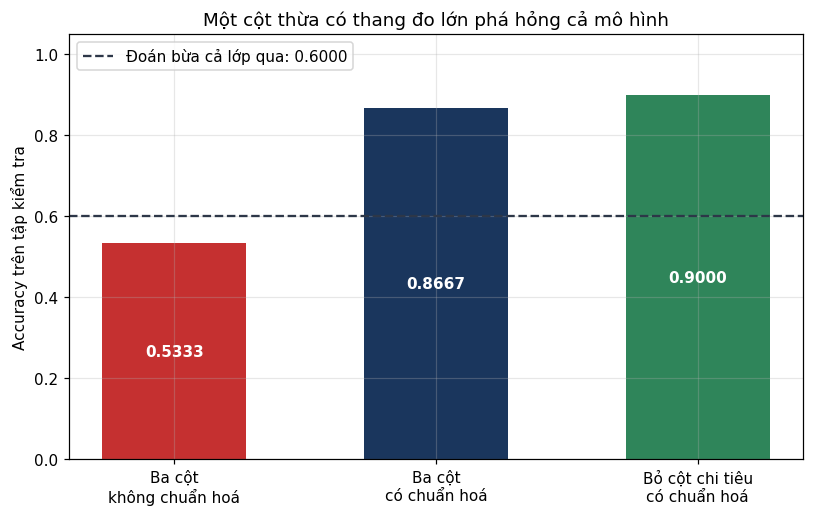

In [5]:
# Hình 2: accuracy trên tập kiểm tra theo ba cách đưa dữ liệu vào KNN
plt.figure(figsize=(7.5, 4.8))
cot_ve = plt.bar(["Ba cột\nkhông chuẩn hoá", "Ba cột\ncó chuẩn hoá", "Bỏ cột chi tiêu\ncó chuẩn hoá"],
                 [a, b, c], color=[MAU_0, MAU_1, "#2f855a"], width=0.55)
plt.bar_label(cot_ve, labels=[f"{v:.4f}" for v in (a, b, c)], label_type="center",
              color="white", fontweight="bold")
plt.axhline(y_te.mean(), linestyle="--", color="#2d3748", label=f"Đoán bừa cả lớp qua: {y_te.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy trên tập kiểm tra")
plt.title("Một cột thừa có thang đo lớn phá hỏng cả mô hình")
plt.legend(loc="upper left")
plt.tight_layout()
luu_hinh("hinh2_hau_qua_quen_chuan_hoa.png")

**Đọc kết quả:** ba con số kể một câu chuyện rất rõ.

- Không chuẩn hoá, accuracy chỉ đạt **0.5333** — còn **thấp hơn cả đoán bừa**, vì cứ đoán mọi bạn đều qua
  đã được 0.6000.
- Chuẩn hoá xong, accuracy vọt lên **0.8667**.
- Bỏ hẳn cột chi tiêu rồi chuẩn hoá, accuracy đạt **0.9000**.

> **Hai bài học:** thứ nhất, với KNN chuẩn hoá là **bắt buộc**, không phải tuỳ chọn — mô hình dựa hoàn toàn
> vào khoảng cách, nên thang đo quyết định tất cả. Thứ hai, một cột **không liên quan** vẫn làm hại mô hình
> ngay cả khi đã chuẩn hoá: sau chuẩn hoá, cột chi tiêu có sức nặng ngang hai cột kia, nên nó vẫn góp nhiều
> "nhiễu" vào khoảng cách. Chọn đúng cột đưa vào mô hình cũng quan trọng như chuẩn hoá.

### Vì sao phải dùng `make_pipeline`

Trong mã, chuẩn hoá và KNN được gộp làm một bằng `make_pipeline`. Khi gọi `.fit` trên tập học, pipeline
tính trung bình và độ lệch chuẩn **chỉ trên tập học**. Khi gọi `.predict` trên tập kiểm tra, nó dùng lại
đúng hai con số đó.

> ⚠️ **Lỗi rò rỉ dữ liệu hay gặp:** chuẩn hoá toàn bộ dữ liệu trước rồi mới chia tập học và tập kiểm tra.
> Làm vậy thì trung bình và độ lệch chuẩn đã được tính có cả tập kiểm tra, tức mô hình **nhìn trộm đề thi**
> trước khi thi. Dùng `make_pipeline` là cách chắc ăn nhất để không mắc lỗi này.

---
## Bước 3 — Chọn số láng giềng *(Mục 4, `e3_chon_k.py`)*

### Bộ dữ liệu hai vầng trăng

Tệp `hai_vang_trang.csv` có 300 điểm chia đều hai lớp, mỗi lớp nằm trên một vầng trăng khuyết lồng vào
nhau. Hai cột `x1` và `x2` có độ lệch chuẩn chênh nhau chỉ khoảng 1.6 lần, nên ở bộ này không chuẩn hoá
cũng được.

Kich thuoc: (300, 3) | so diem moi lop: {0: 150, 1: 150}
Do lech chuan: x1 = 0.912, x2 = 0.571, ty so = 1.60


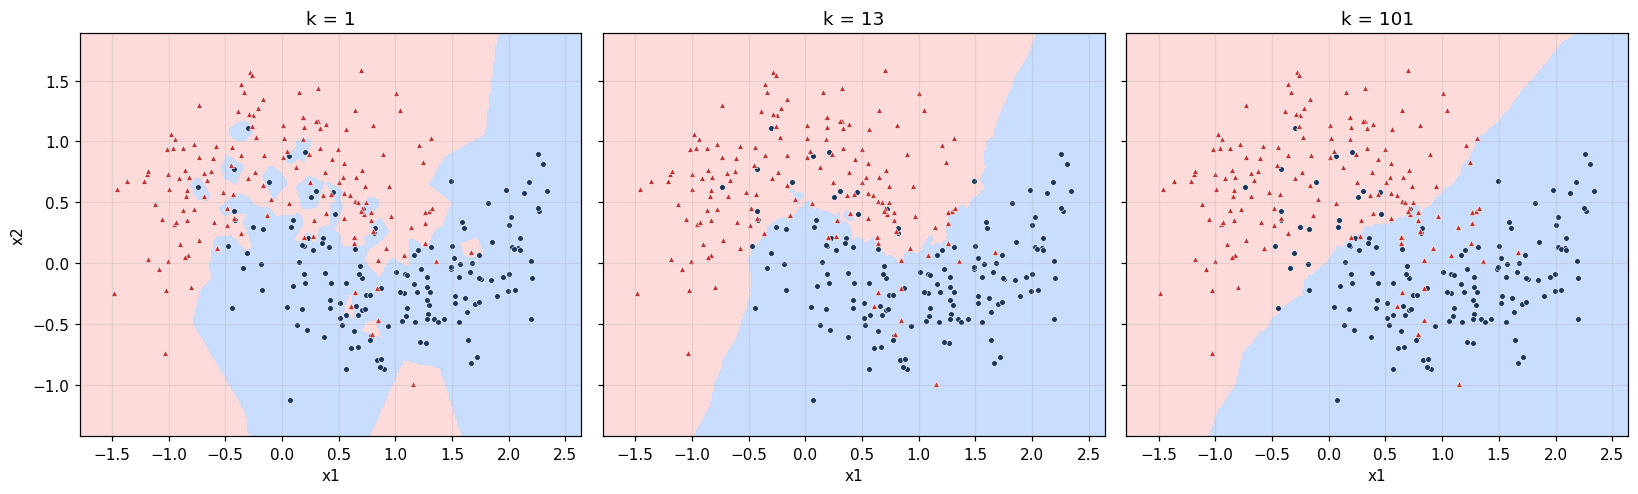

In [6]:
# Hình 3: biên quyết định của KNN với ba giá trị k trên cùng bộ dữ liệu
trang = pd.read_csv(DUONG_DAN_TRANG)
print("Kich thuoc:", trang.shape, "| so diem moi lop:", trang["nhan"].value_counts().to_dict())
print(f"Do lech chuan: x1 = {trang['x1'].std():.3f}, x2 = {trang['x2'].std():.3f}, "
      f"ty so = {trang['x1'].std() / trang['x2'].std():.2f}")

X_trang = trang[["x1", "x2"]]
y_trang = trang["nhan"]
X_tr_trang, _, y_tr_trang, _ = train_test_split(
    X_trang, y_trang, test_size=0.25, random_state=17, stratify=y_trang
)

fig, cac_truc = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, k in zip(cac_truc, [1, 13, 101]):
    mo_hinh_k = KNeighborsClassifier(n_neighbors=k).fit(X_tr_trang, y_tr_trang)
    ve_bien(ax, mo_hinh_k, X_trang, y_trang)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("x1")
cac_truc[0].set_ylabel("x2")
plt.tight_layout()
luu_hinh("hinh3_bien_theo_k.png")

Hình 3 cho thấy $k$ thay đổi hình dạng biên mạnh tới mức nào. Với $k = 1$, biên gập ghềnh và bám theo
từng điểm nhiễu, mô hình **học vẹt**. Với $k = 13$, biên cong mềm và đi đúng hình dạng hai vầng trăng.
Với $k = 101$, biên gần như thẳng và bỏ qua chi tiết, mô hình **cẩu thả**.

### Đo bằng con số

In [7]:
"""Bước 3: chọn số láng giềng k bằng kiểm định chéo."""

from sklearn.model_selection import cross_val_score

df = pd.read_csv(DUONG_DAN_TRANG)
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai cột x1 và x2 có thang đo gần nhau, độ lệch chuẩn chỉ chênh khoảng
# 1.6 lần, nên ở bộ này không chuẩn hoá cũng được.
print("Accuracy tren tap hoc va tap kiem tra theo k")
print("   k    tap hoc   tap kiem tra")
for k in [1, 5, 13, 31, 101]:
    mh = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {k:3d}   {a_hoc:.4f}     {a_kt:.4f}")
print()

# Chọn k chỉ dựa trên tập học, không nhìn tập kiểm tra
print("Kiem dinh cheo 5 phan tren tap hoc:")
diem = {}
for k in range(1, 52, 2):
    diem[k] = cross_val_score(KNeighborsClassifier(n_neighbors=k),
                              X_tr, y_tr, cv=5).mean()
k_tot = max(diem, key=diem.get)
for k in [1, 5, 9, 13, 17, 25, 51]:
    dau = "  <- tot nhat" if k == k_tot else ""
    print(f"  k = {k:2d}  diem trung binh {diem[k]:.4f}{dau}")
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
mh = KNeighborsClassifier(n_neighbors=k_tot).fit(X_tr, y_tr)
print(f"k tot nhat = {k_tot}")
acc = accuracy_score(y_te, mh.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Accuracy tren tap hoc va tap kiem tra theo k
   k    tap hoc   tap kiem tra
    1   1.0000     0.8000
    5   0.8756     0.9067
   13   0.8844     0.9200
   31   0.8667     0.8933
  101   0.8311     0.8533

Kiem dinh cheo 5 phan tren tap hoc:


  k =  1  diem trung binh 0.7778
  k =  5  diem trung binh 0.8444
  k =  9  diem trung binh 0.8444
  k = 13  diem trung binh 0.8667  <- tot nhat
  k = 17  diem trung binh 0.8533
  k = 25  diem trung binh 0.8622
  k = 51  diem trung binh 0.8533

k tot nhat = 13
Accuracy tren tap kiem tra = 0.9200


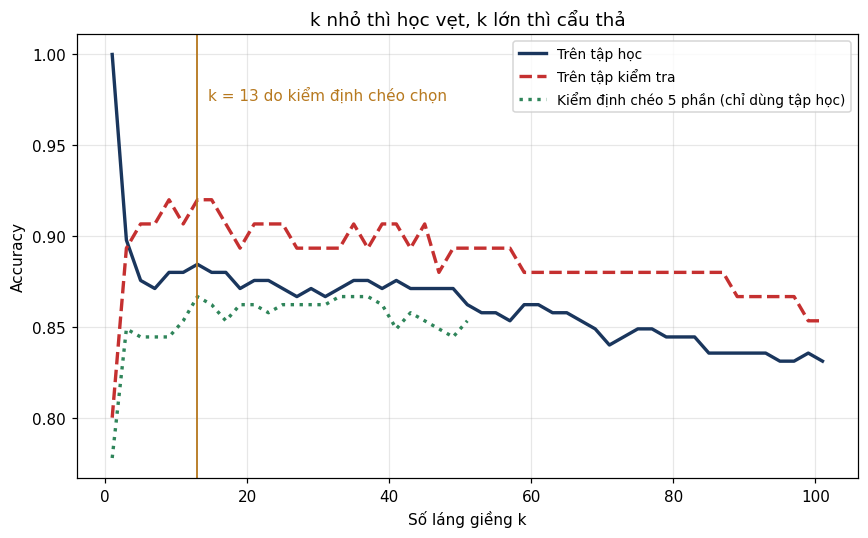

In [8]:
# Hình 4: accuracy trên tập học và tập kiểm tra khi k chạy từ 1 tới 101
cac_k = list(range(1, 102, 2))
acc_hoc, acc_kt = [], []
for k in cac_k:
    mh_k = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    acc_hoc.append(accuracy_score(y_tr, mh_k.predict(X_tr)))
    acc_kt.append(accuracy_score(y_te, mh_k.predict(X_te)))

plt.figure()
plt.plot(cac_k, acc_hoc, color=MAU_1, linewidth=2.2, label="Trên tập học")
plt.plot(cac_k, acc_kt, "--", color=MAU_0, linewidth=2.2, label="Trên tập kiểm tra")
plt.plot(list(diem.keys()), list(diem.values()), ":", color="#2f855a", linewidth=2.2,
         label="Kiểm định chéo 5 phần (chỉ dùng tập học)")
plt.axvline(k_tot, color="#b7791f", linewidth=1.2)
plt.text(k_tot + 1.5, 0.975, f"k = {k_tot} do kiểm định chéo chọn", color="#b7791f")
plt.xlabel("Số láng giềng k")
plt.ylabel("Accuracy")
plt.title("k nhỏ thì học vẹt, k lớn thì cẩu thả")
plt.legend(loc="upper right", fontsize=9)
plt.tight_layout()
luu_hinh("hinh4_accuracy_theo_k.png")

**Đọc kết quả:** với $k = 1$, accuracy trên tập học đạt **1.0000** nhưng trên tập kiểm tra chỉ còn **0.8000**.

> ⚠️ **Vì sao một láng giềng đạt tuyệt đối trên tập học:** mỗi điểm của tập học là láng giềng gần nhất của
> **chính nó** (khoảng cách 0), nên nó luôn tự bỏ phiếu đúng cho mình. Con số 1.0000 đó không nói lên điều
> gì, và đây là lý do không bao giờ chấm điểm trên tập học.

Phần kiểm định chéo chọn ra $k = 13$ với điểm trung bình **0.8667**, chỉ dựa trên tập học. Chọn xong mới
mở tập kiểm tra ra chấm **một lần**, được **0.9200**.

> **Vì sao không chọn $k$ bằng tập kiểm tra:** nhìn bảng đầu tiên thì $k = 13$ cũng đang cho điểm kiểm tra
> cao nhất. Nhưng nếu ta chọn $k$ bằng cách nhìn bảng đó, tập kiểm tra đã bị dùng để ra quyết định, và con
> số 0.9200 không còn là điểm của một bài thi chưa từng thấy. **Kiểm định chéo** chia tập học thành 5 phần,
> lần lượt lấy mỗi phần làm đề thử và 4 phần còn lại để học, rồi lấy trung bình 5 lần chấm. Nhờ vậy ta có
> một thước đo đáng tin để chọn $k$ mà tập kiểm tra vẫn còn nguyên vẹn. Trên Hình 4, đường chấm xanh lá là
> thước đo đó.

> 💡 **Chọn $k$ lẻ:** với bài toán hai lớp, $k$ chẵn có thể dẫn tới hoà phiếu (hai phiếu qua, hai phiếu rớt).
> Chọn $k$ lẻ thì chuyện đó không bao giờ xảy ra, nên vòng lặp trong mã chỉ thử các giá trị lẻ.

---
## Bước 4 — So với các mô hình đã học *(Mục 5, `e4_so_sanh.py`)*

In [9]:
"""Bước 4: đặt KNN cạnh hai mô hình đã học trên dữ liệu có biên cong."""

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

df = pd.read_csv(DUONG_DAN_TRANG)
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cac_mo_hinh = [
    ("Hoi quy logistic", LogisticRegression()),
    ("Naive Bayes     ", GaussianNB()),
    ("KNN, k = 13     ", KNeighborsClassifier(n_neighbors=13)),
]

print("Accuracy tren tap kiem tra, bo hai vang trang")
for ten, mh in cac_mo_hinh:
    mh.fit(X_tr, y_tr)
    print(f"  {ten}: {accuracy_score(y_te, mh.predict(X_te)):.4f}")

Accuracy tren tap kiem tra, bo hai vang trang
  Hoi quy logistic: 0.8533
  Naive Bayes     : 0.8533
  KNN, k = 13     : 0.9200


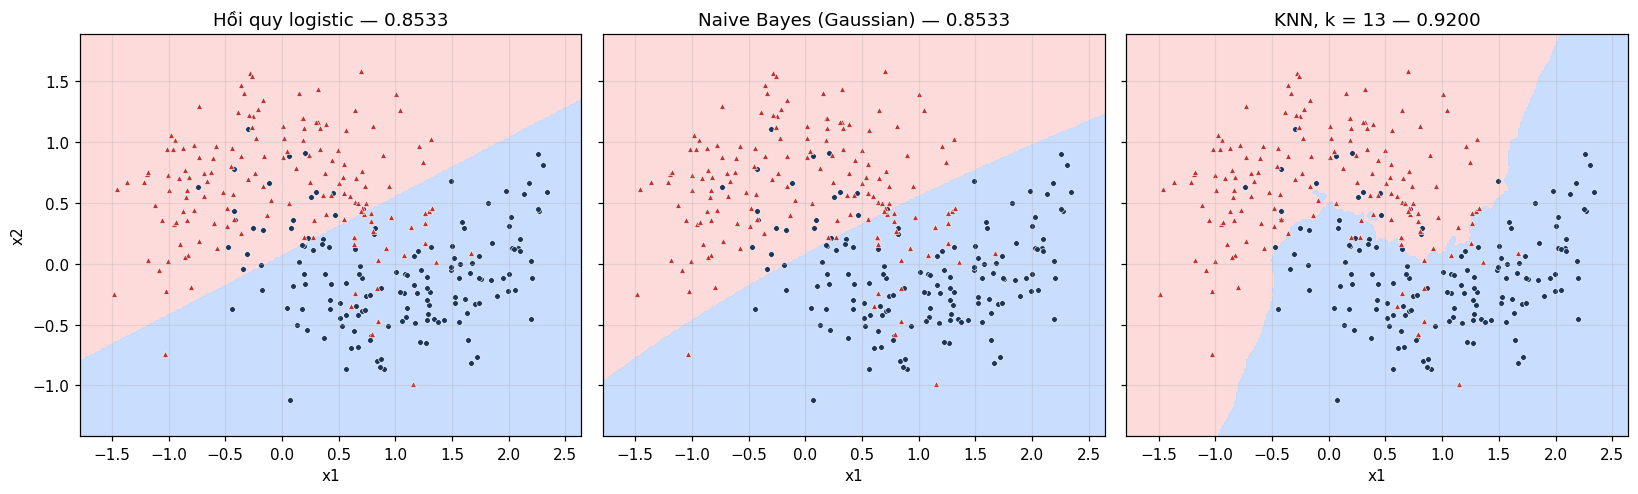

In [10]:
# Hình 5: biên quyết định của hồi quy logistic, Naive Bayes và KNN với k = 13
fig, cac_truc = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
ten_hien_thi = {"Hoi quy logistic": "Hồi quy logistic", "Naive Bayes": "Naive Bayes (Gaussian)",
                "KNN, k = 13": "KNN, k = 13"}
for ax, (ten, mh) in zip(cac_truc, cac_mo_hinh):
    ve_bien(ax, mh, X, y)
    ax.set_title(f"{ten_hien_thi[ten.strip()]} — {accuracy_score(y_te, mh.predict(X_te)):.4f}")
    ax.set_xlabel("x1")
cac_truc[0].set_ylabel("x2")
plt.tight_layout()
luu_hinh("hinh5_so_sanh_ba_mo_hinh.png")

**Đọc kết quả:** hồi quy logistic và Naive Bayes cùng đạt **0.8533**, còn KNN đạt **0.9200**.

Lý do nằm ở Hình 5. Hồi quy logistic chỉ vẽ được một **đường thẳng**, nên nó cắt ngang qua hai vầng trăng
và chấp nhận sai ở hai đầu. Naive Bayes (Gaussian) về lý thuyết vẽ được biên cong, nhưng hình dạng đó do hai
đường chuông quyết định chứ không phải do dữ liệu; ở đây hai lớp có độ phân tán gần nhau nên biên của nó **gần như
thẳng**, cắt hai vầng trăng y như hồi quy logistic. KNN không có dạng
biên cố định nào, nó **tự uốn theo dữ liệu**.

> **Mô hình không tham số:** KNN không giả định biên có hình gì, nên gọi là mô hình **không tham số**
> (*non-parametric*). Dữ liệu có hình dạng lạ tới đâu nó cũng bám theo được, miễn là có đủ dữ liệu. Cái giá
> phải trả là KNN cần nhiều dữ liệu hơn và dự đoán chậm hơn.

### Điểm yếu lớn nhất của KNN *(Hình 6)*

Rải ngẫu nhiên 500 điểm trong một khối lập phương $d$ chiều, chọn thêm một điểm nữa rồi đo tỷ số giữa
khoảng cách tới **láng giềng gần nhất** và tới **láng giềng xa nhất**.

 So chieu   Gan nhat / xa nhat
      1        0.002
      2        0.012
      5        0.108
     10        0.314
     20        0.421
     50        0.633
    100        0.741
    500        0.860


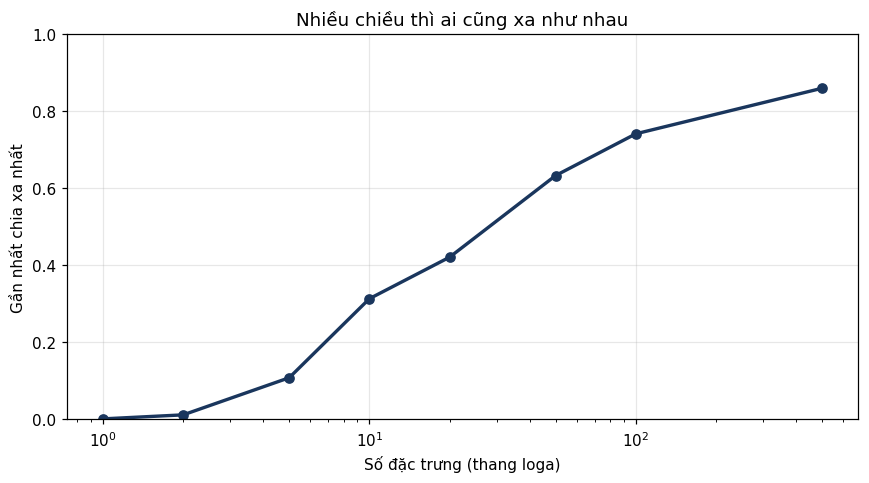

In [11]:
# Hình 6: nhiều chiều thì ai cũng xa như nhau
bo_sinh_so = np.random.default_rng(0)
cac_so_chieu = [1, 2, 5, 10, 20, 50, 100, 500]
ty_so_gan_xa = []
for so_chieu in cac_so_chieu:
    diem_rai = bo_sinh_so.random((500, so_chieu))
    diem_hoi = bo_sinh_so.random(so_chieu)
    khoang_cach = np.sqrt(((diem_rai - diem_hoi) ** 2).sum(axis=1))
    ty_so_gan_xa.append(khoang_cach.min() / khoang_cach.max())

print(" So chieu   Gan nhat / xa nhat")
for so_chieu, ty_so in zip(cac_so_chieu, ty_so_gan_xa):
    print(f"   {so_chieu:4d}        {ty_so:.3f}")

plt.figure(figsize=(8, 4.5))
plt.plot(cac_so_chieu, ty_so_gan_xa, "-o", color=MAU_1, linewidth=2.2)
plt.xscale("log")
plt.ylim(0, 1)
plt.xlabel("Số đặc trưng (thang loga)")
plt.ylabel("Gần nhất chia xa nhất")
plt.title("Nhiều chiều thì ai cũng xa như nhau")
plt.tight_layout()
luu_hinh("hinh6_loi_nguyen_so_chieu.png")

Với 2 đặc trưng, tỷ số chỉ khoảng **0.01** — láng giềng gần nhất gần hơn láng giềng xa nhất cả trăm lần.
Nhưng với 500 đặc trưng, nó lên tới **0.86**.

> ⚠️ **Điểm yếu lớn nhất của KNN:** khi tỷ số gần 1, láng giềng gần nhất cũng xa gần bằng láng giềng xa nhất,
> và việc "hỏi hàng xóm" chẳng còn đáng tin. Đây là **lời nguyền số chiều** đã gặp ở bài 3. Vì vậy KNN hợp
> với bài toán **ít đặc trưng**.

---
## Bước 5 — KNN cho bài toán hồi quy *(Mục 6, `e5_knn_hoi_quy.py`)*

KNN không chỉ phân loại được. Muốn đoán một con số, ta tìm $k$ mẫu gần nhất rồi **lấy trung bình** con số
của chúng thay vì bỏ phiếu. Trong scikit-learn, lớp tương ứng là `KNeighborsRegressor`.

In [12]:
"""Bước 5: KNN cho bài toán hồi quy, trên dữ liệu giá nhà của bài 1."""

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv(DUONG_DAN_NHA)
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

knn = KNeighborsRegressor(n_neighbors=5).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print("MAE tren tap kiem tra (ty dong)")
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  KNN, k = 5  : {mae_knn:.4f}")
print(f"  Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich     KNN   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], knn.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2   {a:6.2f}   {b:6.2f}")
print()

# Năm láng giềng của căn 250 m2 chính là những căn rộng nhất đã thấy
_, chi_so = knn.kneighbors(pd.DataFrame({"dien_tich": [250.0]}))
lg = X_tr.iloc[chi_so[0]]["dien_tich"].tolist()
print("Nam lang gieng cua can 250 m2:", ", ".join(f"{v:.1f}" for v in lg))

MAE tren tap kiem tra (ty dong)
  KNN, k = 5  : 0.4030
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich     KNN   duong thang
      60 m2     4.95     5.12
     100 m2     8.32     8.24
     150 m2     9.32    12.13
     250 m2     9.32    19.91

Nam lang gieng cua can 250 m2: 117.5, 115.9, 111.7, 111.2, 104.2


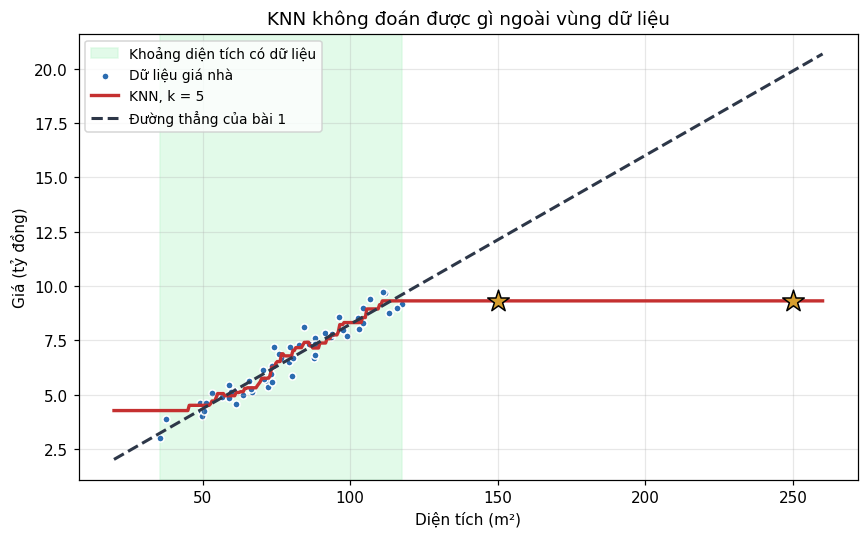

In [13]:
# Hình 7: KNN không đoán được gì ngoài vùng dữ liệu
luoi_dt = pd.DataFrame({"dien_tich": np.linspace(20, 260, 500)})

plt.figure()
plt.axvspan(df["dien_tich"].min(), df["dien_tich"].max(), color="#c6f6d5", alpha=0.5,
            label="Khoảng diện tích có dữ liệu")
plt.scatter(df["dien_tich"], df["gia"], s=22, color="#2b6cb0", edgecolor="white", label="Dữ liệu giá nhà")
plt.plot(luoi_dt["dien_tich"], knn.predict(luoi_dt), color=MAU_0, linewidth=2.2, label="KNN, k = 5")
plt.plot(luoi_dt["dien_tich"], duong.predict(luoi_dt), "--", color="#2d3748", linewidth=2,
         label="Đường thẳng của bài 1")
for dt in [150, 250]:
    plt.scatter([dt], knn.predict(pd.DataFrame({"dien_tich": [dt]})), marker="*", s=220,
                color="#d69e2e", edgecolor="black", zorder=5)
plt.xlabel("Diện tích (m²)")
plt.ylabel("Giá (tỷ đồng)")
plt.title("KNN không đoán được gì ngoài vùng dữ liệu")
plt.legend(loc="upper left", fontsize=9)
plt.tight_layout()
luu_hinh("hinh7_knn_hoi_quy_gia_nha.png")

**Đọc kết quả:** trên dữ liệu giá nhà, đường thẳng thắng: MAE **0.2578** tỷ so với **0.4030** tỷ của KNN.
Điều này hợp lý, vì giá nhà trong bộ dữ liệu tăng gần như thẳng theo diện tích, nên mô hình giả định
đường thẳng là giả định đúng và nó tận dụng triệt để.

Bảng dự đoán cho bốn căn mới mới là chỗ đáng chú ý. Với căn 60 m² và 100 m², hai mô hình đoán gần nhau.
Nhưng căn **150 m²** và căn **250 m²** đều được KNN đoán đúng một con số **9.32 tỷ** (hai ngôi sao vàng
trên hình nằm ngang nhau).

> ⚠️ **KNN không ngoại suy được.** Năm láng giềng của căn 250 m² là năm căn thuộc nhóm rộng nhất trong tập
> học, từ 104.2 tới 117.5 m². Căn 150 m² cũng có đúng năm láng giềng đó, nên hai căn nhận cùng một dự đoán.
> KNN chỉ nói lại những gì đã thấy, **không bao giờ đi xa hơn vùng có dữ liệu**. Đường thẳng thì cứ kéo dài
> mãi — vừa là sức mạnh vừa là mối nguy như bài 1 đã cảnh báo. Đường đỏ trên Hình 7 nằm ngang ở hai đầu
> chính vì thế.

> **Bài học chung của cả buổi:** không có mô hình nào tốt nhất cho mọi bài toán. Trên hai vầng trăng, KNN
> thắng vì biên cong. Trên giá nhà, đường thẳng thắng vì quan hệ thật sự gần như thẳng. Chính **hình dạng
> thật của dữ liệu** quyết định mô hình nào hợp, và đó là lý do phải luôn vẽ dữ liệu ra nhìn trước.

---
# Phần B — Bài tập *(Mục 7)*

**Tiêu chí chấm:** mã chạy được không lỗi, kết quả in ra đúng, có nhận xét bằng lời ở những bài yêu cầu,
tên biến đặt có nghĩa. Riêng **bài 1 và bài 3 chấm nặng phần giải thích**, vì đó là chỗ kiểm tra sinh viên
có hiểu KNN thật sự làm gì bên trong hay không.

> 📌 **Lưu ý khi nộp bài:** thầy yêu cầu mỗi bài là **một tệp `.py` riêng** trong thư mục `baitap04`
> (`bai1.py` … `bai6.py`), chạy bằng `python baitap04/bai1.py` từ thư mục gốc. Notebook này dùng để làm và
> kiểm tra kết quả; khi nộp thì chép nội dung từng ô mã sang tệp `.py` tương ứng, thêm các dòng `import` ở
> đầu và để đường dẫn là `data/...`.

## Bài tập 1 — Tự viết KNN không dùng thư viện

Dựa vào `e1_khoang_cach.py`, viết hàm `knn_du_doan(X_hoc, y_hoc, x_moi, k)` trả về nhãn dự đoán cho một
mẫu mới. Dùng hàm đó dự đoán cho toàn bộ tập kiểm tra của bộ hai vầng trăng với $k = 13$, rồi tính
accuracy. So với `KNeighborsClassifier` ở Bước 3 — hai con số phải bằng nhau. Gợi ý: dùng `np.argsort`
để lấy chỉ số của $k$ khoảng cách nhỏ nhất.

In [14]:
"""Bai 1: tu viet KNN bang numpy va so voi KNeighborsClassifier."""

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

SO_LANG_GIENG = 13


def knn_du_doan(X_hoc, y_hoc, x_moi, k):
    """Du doan nhan cho mot mau moi bang k lang gieng gan nhat.

    Buoc 1: tinh khoang cach Euclid tu x_moi toi MOI mau trong tap hoc.
    Buoc 2: lay chi so cua k khoang cach nho nhat.
    Buoc 3: cho k mau do bo phieu, lop nhieu phieu hon thang.
    """
    khoang_cach = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))
    chi_so_gan_nhat = np.argsort(khoang_cach, kind="stable")[:k]
    phieu = np.bincount(y_hoc[chi_so_gan_nhat], minlength=2)
    return int(np.argmax(phieu))          # hoa phieu thi chon nhan nho hon, giong scikit-learn


vang_trang = pd.read_csv(DUONG_DAN_TRANG)
X_vt = vang_trang[["x1", "x2"]]
y_vt = vang_trang["nhan"]
X_hoc_df, X_kt_df, y_hoc_s, y_kt_s = train_test_split(
    X_vt, y_vt, test_size=0.25, random_state=17, stratify=y_vt
)
# Chuyen sang mang numpy de tinh toan cho nhanh
X_hoc, X_kt = X_hoc_df.to_numpy(), X_kt_df.to_numpy()
y_hoc, y_kt = y_hoc_s.to_numpy(), y_kt_s.to_numpy()

du_doan_tu_viet = np.array([knn_du_doan(X_hoc, y_hoc, x, SO_LANG_GIENG) for x in X_kt])
du_doan_thu_vien = KNeighborsClassifier(n_neighbors=SO_LANG_GIENG).fit(X_hoc, y_hoc).predict(X_kt)

acc_tu_viet = accuracy_score(y_kt, du_doan_tu_viet)
acc_thu_vien = accuracy_score(y_kt, du_doan_thu_vien)
print(f"So mau hoc / kiem tra       : {len(X_hoc)} / {len(X_kt)}")
print(f"Accuracy KNN tu viet, k = {SO_LANG_GIENG} : {acc_tu_viet:.4f}")
print(f"Accuracy KNeighborsClassifier: {acc_thu_vien:.4f}")
print(f"So mau hai ben du doan khac nhau: {(du_doan_tu_viet != du_doan_thu_vien).sum()}")
print()

# Soi mot mau kiem tra cu the de thay ba buoc cua thuat toan
x_vi_du = X_kt[0]
khoang_vi_du = np.sqrt(((X_hoc - x_vi_du) ** 2).sum(axis=1))
gan_vi_du = np.argsort(khoang_vi_du, kind="stable")[:SO_LANG_GIENG]
print(f"Vi du mau kiem tra dau tien: x1 = {x_vi_du[0]:.4f}, x2 = {x_vi_du[1]:.4f}, nhan that = {y_kt[0]}")
print(f"  13 khoang cach nho nhat: {np.round(khoang_vi_du[gan_vi_du], 3).tolist()}")
print(f"  nhan cua 13 lang gieng : {y_hoc[gan_vi_du].tolist()}")
print(f"  bo phieu: {np.bincount(y_hoc[gan_vi_du], minlength=2).tolist()} -> du doan {knn_du_doan(X_hoc, y_hoc, x_vi_du, 13)}")

So mau hoc / kiem tra       : 225 / 75
Accuracy KNN tu viet, k = 13 : 0.9200
Accuracy KNeighborsClassifier: 0.9200
So mau hai ben du doan khac nhau: 0

Vi du mau kiem tra dau tien: x1 = -0.8288, x2 = 0.0701, nhan that = 0
  13 khoang cach nho nhat: [0.033, 0.114, 0.156, 0.182, 0.282, 0.284, 0.286, 0.29, 0.35, 0.351, 0.364, 0.378, 0.42]
  nhan cua 13 lang gieng : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
  bo phieu: [12, 1] -> du doan 0


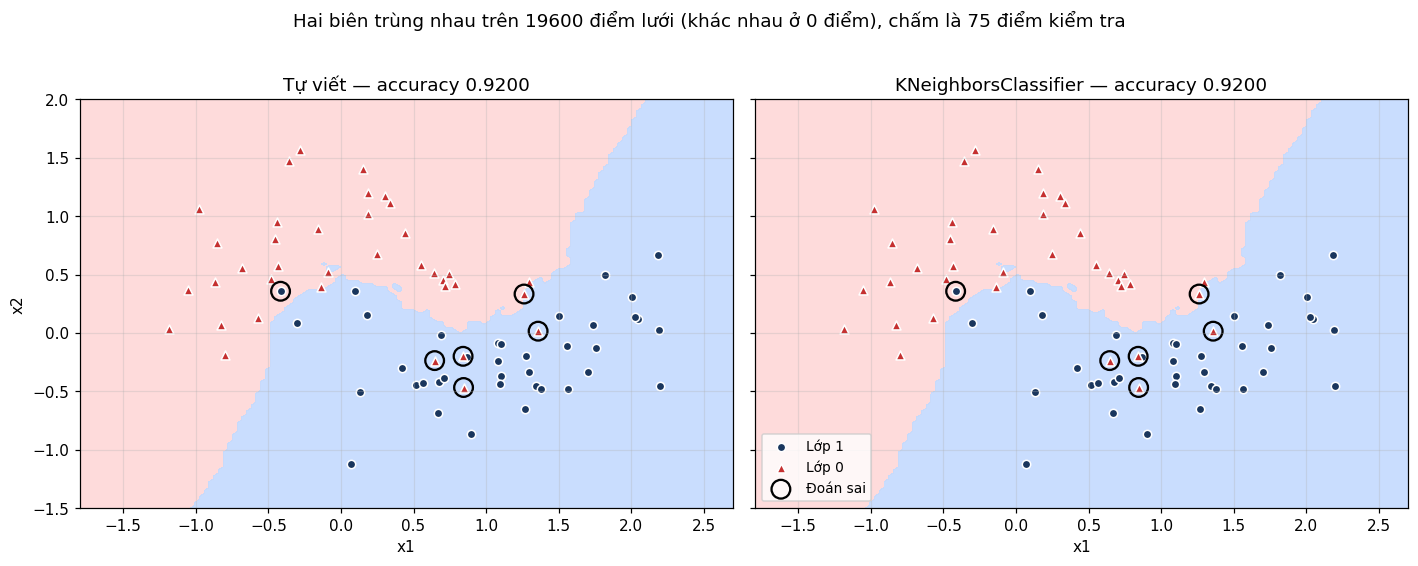

In [15]:
# Ve bien quyet dinh cua chinh ham tu viet tren mot luoi diem
luoi_a, luoi_b = np.meshgrid(np.linspace(-1.8, 2.7, 140), np.linspace(-1.5, 2.0, 140))
luoi_diem = np.column_stack([luoi_a.ravel(), luoi_b.ravel()])
vung_tu_viet = np.array([knn_du_doan(X_hoc, y_hoc, p, SO_LANG_GIENG) for p in luoi_diem])
vung_thu_vien = KNeighborsClassifier(n_neighbors=SO_LANG_GIENG).fit(X_hoc, y_hoc).predict(luoi_diem)

fig, cac_truc = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, vung, ten in [(cac_truc[0], vung_tu_viet, f"Tự viết — accuracy {acc_tu_viet:.4f}"),
                      (cac_truc[1], vung_thu_vien, f"KNeighborsClassifier — accuracy {acc_thu_vien:.4f}")]:
    ax.contourf(luoi_a, luoi_b, vung.reshape(luoi_a.shape), levels=[-0.5, 0.5, 1.5],
                colors=[NEN_0, NEN_1], alpha=0.9)
    ax.scatter(X_kt[y_kt == 1, 0], X_kt[y_kt == 1, 1], s=30, color=MAU_1, edgecolor="white", label="Lớp 1")
    ax.scatter(X_kt[y_kt == 0, 0], X_kt[y_kt == 0, 1], s=34, marker="^", color=MAU_0,
               edgecolor="white", label="Lớp 0")
    sai = (du_doan_tu_viet != y_kt)
    ax.scatter(X_kt[sai, 0], X_kt[sai, 1], s=150, facecolor="none", edgecolor="black", linewidth=1.5,
               label="Đoán sai")
    ax.set_title(ten)
    ax.set_xlabel("x1")
cac_truc[0].set_ylabel("x2")
cac_truc[1].legend(loc="lower left", fontsize=9)
plt.suptitle(f"Hai biên trùng nhau trên {len(luoi_diem)} điểm lưới "
             f"(khác nhau ở {(vung_tu_viet != vung_thu_vien).sum()} điểm), chấm là 75 điểm kiểm tra", y=1.02)
plt.tight_layout()
luu_hinh("bai1_knn_tu_viet.png")

**Kết quả:** hàm tự viết đạt accuracy **0.9200**, bằng đúng `KNeighborsClassifier`, và **không có mẫu nào**
hai bên dự đoán khác nhau. Vẽ biên trên gần 20 nghìn điểm lưới cũng trùng nhau hoàn toàn.

**Giải thích — KNN thật sự làm gì bên trong:** hàm `knn_du_doan` chỉ có ba dòng tính toán, ứng đúng ba bước
của thuật toán:

1. **Tính khoảng cách tới mọi mẫu học.** `X_hoc - x_moi` trừ mẫu mới khỏi *cả* 225 dòng cùng lúc (numpy tự
   "kéo dãn" `x_moi` ra cho khớp), bình phương, cộng theo hàng (`axis=1`) rồi lấy căn — đúng công thức
   Euclid, ra một mảng 225 khoảng cách. Không có gì được "học" trước: mọi phép tính diễn ra ngay lúc hỏi,
   đó chính là nghĩa của *học lười*.
2. **Chọn $k$ mẫu gần nhất.** `np.argsort` không trả về khoảng cách đã sắp xếp mà trả về **chỉ số** của
   chúng theo thứ tự tăng dần; lấy 13 chỉ số đầu là được 13 láng giềng. Dùng `kind="stable"` để nếu hai mẫu
   cách đều thì mẫu đứng trước trong tập học được ưu tiên — cùng cách xử lý như thư viện.
3. **Bỏ phiếu.** `np.bincount` đếm số láng giềng mang nhãn 0 và nhãn 1, `np.argmax` chọn nhãn nhiều phiếu hơn.
   Với $k = 13$ lẻ và hai lớp thì không thể hoà phiếu. Ví dụ in ra ở trên cho thấy trọn ba bước cho một mẫu
   cụ thể: 13 khoảng cách nhỏ nhất, nhãn của 13 láng giềng và kết quả đếm phiếu.

Hai con số bằng nhau vì `KNeighborsClassifier` (với mặc định `metric="minkowski", p=2` — tức Euclid — và
`weights="uniform"`) làm **đúng ba bước đó**; khác biệt duy nhất là thư viện dùng cấu trúc cây (*kd-tree*)
để tìm láng giềng nhanh hơn thay vì tính hết 225 khoảng cách, nhưng láng giềng tìm ra vẫn là một. Lưu ý mã
tự viết không chuẩn hoá vì bộ hai vầng trăng không cần (Bước 3); với bộ sinh viên thì phải chuẩn hoá trước
như ở Bước 1, nếu không cột chi tiêu sẽ nuốt trọn khoảng cách.

## Bài tập 2 — Khoảng cách Manhattan

Chạy lại `e3_chon_k.py` nhưng thêm tham số `metric="manhattan"` vào `KNeighborsClassifier`. Ghi lại $k$ tốt
nhất và accuracy trên tập kiểm tra, rồi so với khoảng cách Euclid. Nhận xét: đổi cách đo khoảng cách có làm
kết quả khác đi nhiều không?

Khoảng cách Manhattan cộng **trị tuyệt đối** các chênh lệch thay vì bình phương rồi lấy căn — giống đi bộ
trong thành phố ô bàn cờ, chỉ được đi dọc hoặc ngang:

$$d_{\text{Manhattan}}(\boldsymbol{x}, \boldsymbol{z}) = |x_1 - z_1| + |x_2 - z_2| + \dots + |x_d - z_d|$$

In [16]:
"""Bai 2: chon k bang kiem dinh cheo voi hai cach do khoang cach."""

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

vang_trang = pd.read_csv(DUONG_DAN_TRANG)
X_vt = vang_trang[["x1", "x2"]]
y_vt = vang_trang["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X_vt, y_vt, test_size=0.25, random_state=17, stratify=y_vt
)

ket_qua_theo_cach_do = {}
for cach_do in ["euclidean", "manhattan"]:
    diem_kiem_dinh = {
        k: cross_val_score(KNeighborsClassifier(n_neighbors=k, metric=cach_do),
                           X_tr, y_tr, cv=5).mean()
        for k in range(1, 52, 2)
    }
    k_tot_nhat = max(diem_kiem_dinh, key=diem_kiem_dinh.get)
    mo_hinh_tot = KNeighborsClassifier(n_neighbors=k_tot_nhat, metric=cach_do).fit(X_tr, y_tr)
    acc_kiem_tra = accuracy_score(y_te, mo_hinh_tot.predict(X_te))
    ket_qua_theo_cach_do[cach_do] = (diem_kiem_dinh, k_tot_nhat, acc_kiem_tra)
    print(f"{cach_do:10s}: k tot nhat = {k_tot_nhat:2d}, diem kiem dinh cheo = "
          f"{diem_kiem_dinh[k_tot_nhat]:.4f}, accuracy kiem tra = {acc_kiem_tra:.4f}")
print()

print(" k   Euclid   Manhattan   (diem kiem dinh cheo)")
for k in [1, 5, 9, 13, 17, 21, 25, 27, 31, 51]:
    print(f"{k:2d}   {ket_qua_theo_cach_do['euclidean'][0][k]:.4f}    "
          f"{ket_qua_theo_cach_do['manhattan'][0][k]:.4f}")
print()

# Cong bang hon: so hai cach do o CUNG mot k
for k in [13, 27]:
    acc_e = accuracy_score(y_te, KNeighborsClassifier(k).fit(X_tr, y_tr).predict(X_te))
    acc_m = accuracy_score(y_te, KNeighborsClassifier(k, metric="manhattan").fit(X_tr, y_tr).predict(X_te))
    print(f"Cung k = {k}: Euclid {acc_e:.4f}, Manhattan {acc_m:.4f}")

euclidean : k tot nhat = 13, diem kiem dinh cheo = 0.8667, accuracy kiem tra = 0.9200


manhattan : k tot nhat = 27, diem kiem dinh cheo = 0.8667, accuracy kiem tra = 0.9067

 k   Euclid   Manhattan   (diem kiem dinh cheo)
 1   0.7778    0.7822
 5   0.8444    0.8444
 9   0.8444    0.8222
13   0.8667    0.8489
17   0.8533    0.8622
21   0.8622    0.8533
25   0.8622    0.8578
27   0.8622    0.8667
31   0.8622    0.8489
51   0.8533    0.8489

Cung k = 13: Euclid 0.9200, Manhattan 0.9067
Cung k = 27: Euclid 0.8933, Manhattan 0.9067


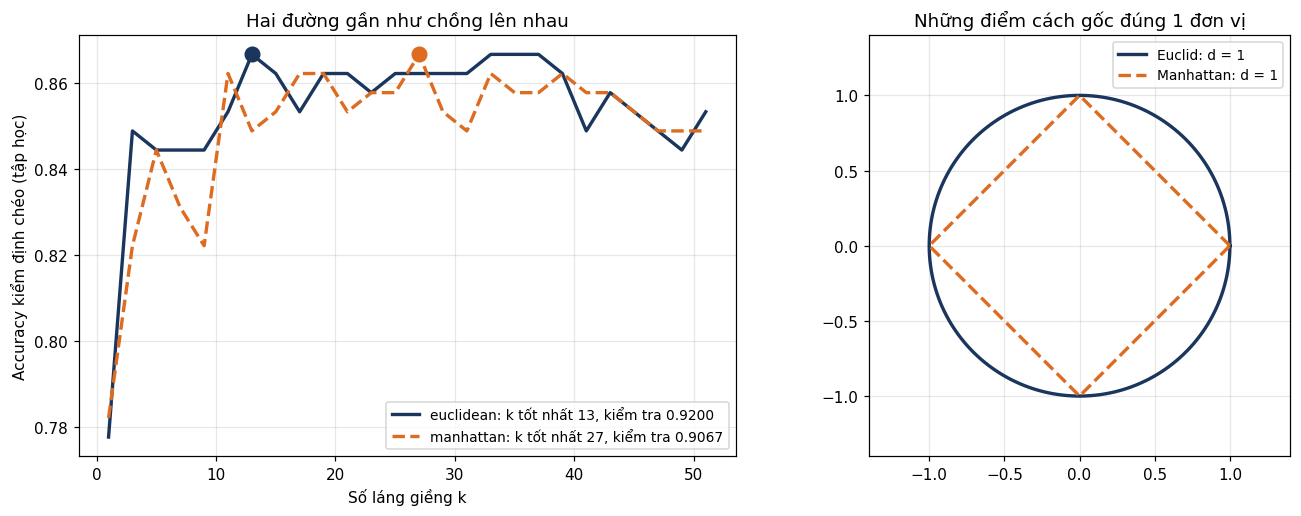

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for cach_do, mau, kieu in [("euclidean", MAU_1, "-"), ("manhattan", "#dd6b20", "--")]:
    diem_kd, k_tot_nhat, acc_kt = ket_qua_theo_cach_do[cach_do]
    ax1.plot(list(diem_kd.keys()), list(diem_kd.values()), kieu, color=mau, linewidth=2.2,
             label=f"{cach_do}: k tốt nhất {k_tot_nhat}, kiểm tra {acc_kt:.4f}")
    ax1.scatter([k_tot_nhat], [diem_kd[k_tot_nhat]], s=90, color=mau, zorder=5)
ax1.set_xlabel("Số láng giềng k")
ax1.set_ylabel("Accuracy kiểm định chéo (tập học)")
ax1.set_title("Hai đường gần như chồng lên nhau")
ax1.legend(loc="lower right", fontsize=9)

# Hinh tron don vi: tap cac diem cach goc dung 1 theo moi cach do
goc = np.linspace(0, 2 * np.pi, 400)
ax2.plot(np.cos(goc), np.sin(goc), color=MAU_1, linewidth=2.2, label="Euclid: d = 1")
ax2.plot([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], "--", color="#dd6b20", linewidth=2.2, label="Manhattan: d = 1")
ax2.set_aspect("equal")
ax2.set_xlim(-1.4, 1.4)
ax2.set_ylim(-1.4, 1.4)
ax2.set_title("Những điểm cách gốc đúng 1 đơn vị")
ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout()
luu_hinh("bai2_euclid_va_manhattan.png")

**Kết quả:**

| Cách đo | $k$ tốt nhất | Điểm kiểm định chéo | Accuracy kiểm tra |
|---|---:|---:|---:|
| Euclid | 13 | 0.8667 | **0.9200** |
| Manhattan | 27 | 0.8667 | **0.9067** |

**Nhận xét:** đổi cách đo khoảng cách **không làm kết quả khác đi nhiều**. Điểm kiểm định chéo cao nhất của
hai cách bằng nhau (0.8667), hai đường trên hình gần như chồng lên nhau, và accuracy kiểm tra chỉ lệch 0.0133
— đúng **1 điểm** trên 75. $k$ tốt nhất nhảy từ 13 sang 27 nghe có vẻ lớn, nhưng đó là vì đường kiểm định chéo
rất phẳng quanh đỉnh: nhiều giá trị $k$ cho điểm gần như nhau nên chỉ cần lệch một chút là "đỉnh" đổi chỗ.
So ở **cùng một $k$** thì không cách nào thắng hẳn: với $k = 13$ Euclid hơn 1 điểm, với $k = 27$ Manhattan
lại hơn 1 điểm.

Lý do: với chỉ **2 đặc trưng** có thang đo gần nhau, thứ tự "ai gần ai" theo hai cách đo hầu như giống nhau
— hình tròn và hình thoi đơn vị ở hình bên phải chỉ khác nhau ở các góc chéo. Cách đo khoảng cách sẽ quan
trọng hơn khi có nhiều đặc trưng hoặc dữ liệu có ngoại lai (Manhattan ít bị một chênh lệch lớn chi phối hơn,
vì nó không bình phương). Với bài này, **chọn $k$ và chuẩn hoá quan trọng hơn chọn cách đo**.

## Bài tập 3 — Đổi đơn vị đo

Trên bộ `sinh_vien_mo_rong.csv`, đổi cột `chi_tieu` từ **nghìn đồng** sang **triệu đồng** bằng cách chia cho
1000. Chạy KNN với $k = 7$ **không chuẩn hoá** trên ba cột mới. Accuracy thay đổi thế nào so với 0.5333 ở
Bước 2? Giải thích vì sao chỉ đổi đơn vị mà kết quả lại khác hẳn. Nếu có chuẩn hoá thì đổi đơn vị có làm
kết quả thay đổi không?

In [18]:
"""Bai 3: doi don vi cot chi_tieu va xem KNN khong chuan hoa phan ung the nao."""

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sinh_vien = pd.read_csv(DUONG_DAN_SV)
nhan_qua_mon = sinh_vien["qua_mon"]
BA_COT = ["gio_on", "diem_giua_ky", "chi_tieu"]

# Ba don vi cho cung mot cot chi tieu: dong, nghin dong (goc), trieu dong
cac_don_vi = {"dong": 1000.0, "nghin dong (goc)": 1.0, "trieu dong": 1 / 1000}

bang_ket_qua = []
for ten_don_vi, he_so_doi in cac_don_vi.items():
    du_lieu = sinh_vien[BA_COT].copy()
    du_lieu["chi_tieu"] = du_lieu["chi_tieu"] * he_so_doi
    X_hoc, X_kt, y_hoc, y_kt = train_test_split(
        du_lieu, nhan_qua_mon, test_size=0.25, random_state=17, stratify=nhan_qua_mon
    )
    acc_khong_chuan = accuracy_score(y_kt, KNeighborsClassifier(7).fit(X_hoc, y_hoc).predict(X_kt))
    acc_co_chuan = accuracy_score(
        y_kt, make_pipeline(StandardScaler(), KNeighborsClassifier(7)).fit(X_hoc, y_hoc).predict(X_kt))
    do_lech = du_lieu.std(ddof=0)
    bang_ket_qua.append({
        "don_vi_chi_tieu": ten_don_vi,
        "do_lech_gio_on": do_lech["gio_on"],
        "do_lech_diem": do_lech["diem_giua_ky"],
        "do_lech_chi_tieu": do_lech["chi_tieu"],
        "acc_khong_chuan_hoa": acc_khong_chuan,
        "acc_co_chuan_hoa": acc_co_chuan,
    })

bang_ket_qua = pd.DataFrame(bang_ket_qua)
print(bang_ket_qua.round(4).to_string(index=False))
print()
print(f"Doan bua ca lop qua: {y_kt.mean():.4f}")
print()

# Moi cot gop bao nhieu phan vao binh phuong khoang cach giua hai ban "dien hinh"?
# Lay chenh lech dien hinh cua moi cot bang chinh do lech chuan cua cot do.
for _, dong in bang_ket_qua.iterrows():
    binh_phuong = np.array([dong["do_lech_gio_on"], dong["do_lech_diem"], dong["do_lech_chi_tieu"]]) ** 2
    phan_tram = 100 * binh_phuong / binh_phuong.sum()
    print(f"{dong['don_vi_chi_tieu']:18s}: gio_on {phan_tram[0]:6.2f}%  diem {phan_tram[1]:6.2f}%  "
          f"chi_tieu {phan_tram[2]:6.2f}%  cua khoang cach")

 don_vi_chi_tieu  do_lech_gio_on  do_lech_diem  do_lech_chi_tieu  acc_khong_chuan_hoa  acc_co_chuan_hoa
            dong          7.8176        2.0903      1691670.7204               0.5333            0.8667
nghin dong (goc)          7.8176        2.0903         1691.6707               0.5333            0.8667
      trieu dong          7.8176        2.0903            1.6917               0.8667            0.8667

Doan bua ca lop qua: 0.6000

dong              : gio_on   0.00%  diem   0.00%  chi_tieu 100.00%  cua khoang cach
nghin dong (goc)  : gio_on   0.00%  diem   0.00%  chi_tieu 100.00%  cua khoang cach
trieu dong        : gio_on  89.42%  diem   6.39%  chi_tieu   4.19%  cua khoang cach


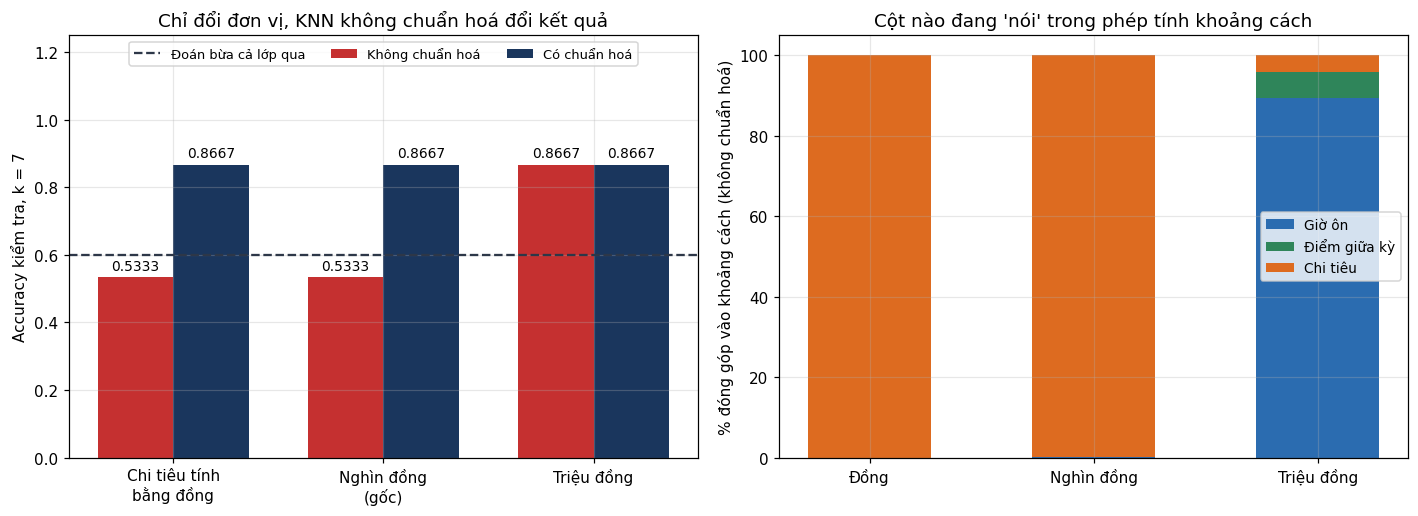

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
vi_tri = np.arange(len(bang_ket_qua))
do_rong = 0.36
cot_khong = ax1.bar(vi_tri - do_rong / 2, bang_ket_qua["acc_khong_chuan_hoa"], do_rong, color=MAU_0,
                    label="Không chuẩn hoá")
cot_co = ax1.bar(vi_tri + do_rong / 2, bang_ket_qua["acc_co_chuan_hoa"], do_rong, color=MAU_1,
                 label="Có chuẩn hoá")
ax1.bar_label(cot_khong, fmt="%.4f", padding=3, fontsize=9)
ax1.bar_label(cot_co, fmt="%.4f", padding=3, fontsize=9)
ax1.axhline(y_kt.mean(), linestyle="--", color="#2d3748", label="Đoán bừa cả lớp qua")
ax1.set_xticks(vi_tri, ["Chi tiêu tính\nbằng đồng", "Nghìn đồng\n(gốc)", "Triệu đồng"])
ax1.set_ylim(0, 1.25)
ax1.set_ylabel("Accuracy kiểm tra, k = 7")
ax1.set_title("Chỉ đổi đơn vị, KNN không chuẩn hoá đổi kết quả")
ax1.legend(loc="upper center", ncol=3, fontsize=8.5)

# Phan dong gop cua tung cot vao khoang cach (khong chuan hoa)
dong_gop = (bang_ket_qua[["do_lech_gio_on", "do_lech_diem", "do_lech_chi_tieu"]] ** 2)
dong_gop = dong_gop.div(dong_gop.sum(axis=1), axis=0) * 100
day = np.zeros(len(bang_ket_qua))
for cot, mau, ten in [("do_lech_gio_on", "#2b6cb0", "Giờ ôn"), ("do_lech_diem", "#2f855a", "Điểm giữa kỳ"),
                      ("do_lech_chi_tieu", "#dd6b20", "Chi tiêu")]:
    ax2.bar(vi_tri, dong_gop[cot], bottom=day, color=mau, width=0.55, label=ten)
    day += dong_gop[cot].to_numpy()
ax2.set_xticks(vi_tri, ["Đồng", "Nghìn đồng", "Triệu đồng"])
ax2.set_ylabel("% đóng góp vào khoảng cách (không chuẩn hoá)")
ax2.set_title("Cột nào đang 'nói' trong phép tính khoảng cách")
ax2.legend(loc="center right", fontsize=9)
plt.tight_layout()
luu_hinh("bai3_doi_don_vi.png")

**Kết quả:**

| Đơn vị của chi tiêu | Độ lệch chuẩn của chi tiêu | Không chuẩn hoá | Có chuẩn hoá |
|---|---:|---:|---:|
| đồng | ≈ 1 691 671 | 0.5333 | 0.8667 |
| nghìn đồng (gốc) | ≈ 1 692 | 0.5333 | 0.8667 |
| **triệu đồng** | **≈ 1.69** | **0.8667** | 0.8667 |

Chỉ chia cột chi tiêu cho 1000, accuracy của KNN không chuẩn hoá nhảy từ **0.5333** (thua cả đoán bừa 0.6000)
lên **0.8667** — bằng đúng KNN có chuẩn hoá.

**Giải thích vì sao chỉ đổi đơn vị mà kết quả khác hẳn:** đổi đơn vị không làm thay đổi *thông tin* trong dữ
liệu — ai tiêu nhiều vẫn tiêu nhiều — nhưng KNN không nhìn thông tin, nó chỉ nhìn **khoảng cách**, mà khoảng
cách Euclid cộng thẳng các chênh lệch bình phương của từng cột. Một cột có con số lớn sẽ có chênh lệch lớn và
chiếm phần lớn tổng đó:

- Khi chi tiêu tính bằng **nghìn đồng**, chênh lệch điển hình của nó cỡ 1692, trong khi giờ ôn cỡ 7.8 và điểm
  cỡ 2.1. Bảng phần trăm ở trên cho thấy chi tiêu chiếm **hơn 99.99%** bình phương khoảng cách: "láng giềng gần
  nhất" thực chất là "người tiêu tiền giống nhất" (bảng làm tròn thành 100.00%). Mà chi tiêu gần như không liên quan tới việc qua môn, nên
  KNN đoán còn tệ hơn đoán bừa. Tính bằng **đồng** thì càng tệ nữa, kết quả y hệt.
- Khi chi tiêu tính bằng **triệu đồng**, độ lệch chuẩn của nó còn khoảng 1.69 — cùng cỡ với điểm giữa kỳ (2.09)
  và nhỏ hơn giờ ôn (7.82). Lúc này **giờ ôn chiếm phần lớn khoảng cách** (khoảng 89%), điểm và chi tiêu chia
  phần còn lại, nên KNN tìm láng giềng chủ yếu theo việc học — và đoán tốt. Kết quả trùng với bản chuẩn hoá ở
  bài này là **một sự trùng hợp may mắn** vì đơn vị triệu đồng *tình cờ* làm ba cột có thang đo gần nhau; chọn
  đơn vị khác (ví dụ chục triệu) thì cân bằng lại lệch đi.

**Nếu có chuẩn hoá thì đổi đơn vị không làm kết quả thay đổi** — cột "có chuẩn hoá" ra 0.8667 ở cả ba đơn vị.
Lý do: chuẩn hoá trừ trung bình rồi chia độ lệch chuẩn. Nhân cả cột với 1000 thì trung bình và độ lệch chuẩn
cũng nhân 1000, hai hệ số triệt tiêu nhau, cột sau chuẩn hoá **giống hệt từng chữ số**. Mỗi cột luôn được đo
bằng "đơn vị độ lệch chuẩn" của chính nó, nên đơn vị gốc không còn ý nghĩa gì.

**Bài học:** với KNN không chuẩn hoá, kết quả phụ thuộc vào việc người nhập liệu ghi đơn vị nào — một quyết
định tuỳ tiện chẳng liên quan gì tới bài toán. Chuẩn hoá loại bỏ sự tuỳ tiện đó, nên nó là **bắt buộc**.

## Bài tập 4 — Láng giềng có trọng số

Thêm tham số `weights="distance"` vào `KNeighborsClassifier`. Khi đó láng giềng càng gần thì phiếu càng nặng
(trọng số bằng $1/\text{khoảng cách}$). Chạy lại với $k = 1, 13, 101$ trên bộ hai vầng trăng và so với bảng ở
Bước 3. Với $k = 101$, trọng số theo khoảng cách có giúp mô hình bớt cẩu thả không? Vì sao?

In [20]:
"""Bai 4: so sanh phieu deu nhau va phieu theo khoang cach."""

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

vang_trang = pd.read_csv(DUONG_DAN_TRANG)
X_vt = vang_trang[["x1", "x2"]]
y_vt = vang_trang["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X_vt, y_vt, test_size=0.25, random_state=17, stratify=y_vt
)

print("   k  |  phieu deu: hoc   kiem tra  |  theo khoang cach: hoc   kiem tra")
cac_mo_hinh_bai4 = {}
for k in [1, 13, 101]:
    deu = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    trong_so = KNeighborsClassifier(n_neighbors=k, weights="distance").fit(X_tr, y_tr)
    cac_mo_hinh_bai4[k] = (deu, trong_so)
    print(f"  {k:3d} |      {accuracy_score(y_tr, deu.predict(X_tr)):.4f}    {accuracy_score(y_te, deu.predict(X_te)):.4f}"
          f"   |         {accuracy_score(y_tr, trong_so.predict(X_tr)):.4f}    "
          f"{accuracy_score(y_te, trong_so.predict(X_te)):.4f}")
print()

# Nhin ben trong mot lan bo phieu voi k = 101: phieu cua 10 lang gieng gan nhat nang bao nhieu?
x_vi_du = X_te.iloc[[0]]
khoang_cach, chi_so = cac_mo_hinh_bai4[101][0].kneighbors(x_vi_du)
trong_so_phieu = 1 / khoang_cach[0]
ty_le_10_gan_nhat = trong_so_phieu[:10].sum() / trong_so_phieu.sum()
print(f"Mau kiem tra dau tien, k = 101:")
print(f"  khoang cach gan nhat {khoang_cach[0][0]:.3f}, xa nhat {khoang_cach[0][-1]:.3f}")
print(f"  10 lang gieng gan nhat chiem {100 * ty_le_10_gan_nhat:.1f}% tong trong so phieu "
      f"(phieu deu thi chi la {100 * 10 / 101:.1f}%)")

   k  |  phieu deu: hoc   kiem tra  |  theo khoang cach: hoc   kiem tra
    1 |      1.0000    0.8000   |         1.0000    0.8000
   13 |      0.8844    0.9200   |         1.0000    0.9333
  101 |      0.8311    0.8533   |         1.0000    0.9067

Mau kiem tra dau tien, k = 101:
  khoang cach gan nhat 0.033, xa nhat 1.388
  10 lang gieng gan nhat chiem 39.6% tong trong so phieu (phieu deu thi chi la 9.9%)


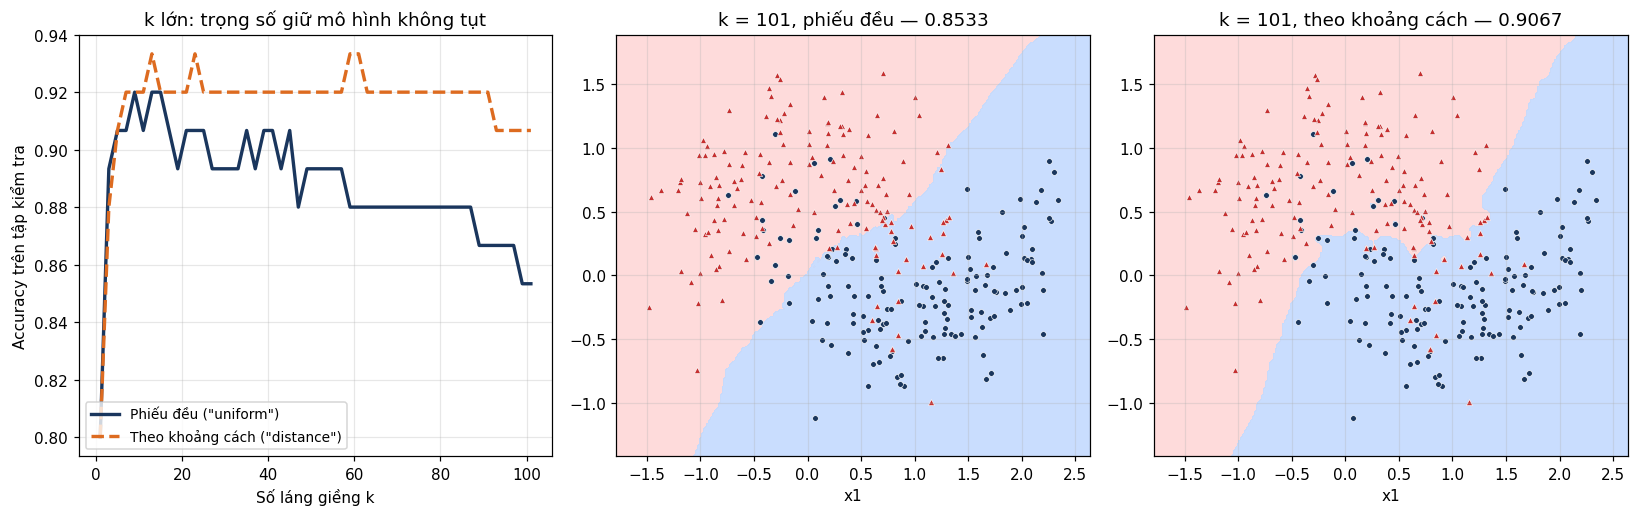

In [21]:
cac_k_bai4 = list(range(1, 102, 2))
acc_deu, acc_trong_so = [], []
for k in cac_k_bai4:
    acc_deu.append(accuracy_score(y_te, KNeighborsClassifier(k).fit(X_tr, y_tr).predict(X_te)))
    acc_trong_so.append(accuracy_score(
        y_te, KNeighborsClassifier(k, weights="distance").fit(X_tr, y_tr).predict(X_te)))

fig = plt.figure(figsize=(15, 4.8))
ax1 = fig.add_subplot(1, 3, 1)
ax1.plot(cac_k_bai4, acc_deu, color=MAU_1, linewidth=2.2, label='Phiếu đều ("uniform")')
ax1.plot(cac_k_bai4, acc_trong_so, "--", color="#dd6b20", linewidth=2.2, label='Theo khoảng cách ("distance")')
ax1.set_xlabel("Số láng giềng k")
ax1.set_ylabel("Accuracy trên tập kiểm tra")
ax1.set_title("k lớn: trọng số giữ mô hình không tụt")
ax1.legend(loc="lower left", fontsize=9)
for vi_tri_truc, (ten, mh) in zip([2, 3], [("k = 101, phiếu đều", cac_mo_hinh_bai4[101][0]),
                                           ("k = 101, theo khoảng cách", cac_mo_hinh_bai4[101][1])]):
    ax = fig.add_subplot(1, 3, vi_tri_truc)
    ve_bien(ax, mh, X_vt, y_vt)
    ax.set_title(f"{ten} — {accuracy_score(y_te, mh.predict(X_te)):.4f}")
    ax.set_xlabel("x1")
plt.tight_layout()
luu_hinh("bai4_lang_gieng_co_trong_so.png")

**Kết quả:**

| $k$ | Phiếu đều: học | Phiếu đều: kiểm tra | Theo khoảng cách: học | Theo khoảng cách: kiểm tra |
|---:|---:|---:|---:|---:|
| 1 | 1.0000 | 0.8000 | 1.0000 | 0.8000 |
| 13 | 0.8844 | 0.9200 | **1.0000** | **0.9333** |
| 101 | 0.8311 | 0.8533 | **1.0000** | **0.9067** |

**Với $k = 101$, trọng số theo khoảng cách giúp mô hình bớt cẩu thả rõ rệt:** accuracy kiểm tra tăng từ
**0.8533 lên 0.9067**, và biên quyết định ở hình bên phải uốn cong theo hai vầng trăng thay vì gần thẳng như
hình giữa.

**Vì sao:** với phiếu đều, 101 láng giềng — gần một nửa tập học 225 điểm — có tiếng nói ngang nhau. Những
điểm ở tận đầu kia của vầng trăng cũng được bỏ phiếu như điểm ngay sát bên, nên chi tiết cục bộ bị "san
phẳng" và biên gần thành đường thẳng. Với trọng số $1/\text{khoảng cách}$, phiếu của láng giềng gần nặng hơn
hẳn phiếu của láng giềng xa: ở mẫu ví dụ, láng giềng gần nhất cách 0.033 còn láng giềng thứ 101 cách 1.388 —
phiếu của người gần nặng gấp hơn 40 lần — và **10 láng giềng gần nhất chiếm 39.6% tổng trọng số**, trong khi
với phiếu đều chúng chỉ chiếm 9.9%. Mô hình vì vậy **tự động thu hẹp "vùng hỏi ý kiến" về gần mẫu mới**
dù $k$ danh nghĩa vẫn là 101 — tương đương một $k$ hiệu dụng nhỏ hơn nhiều, nên bớt cẩu thả.

Với $k = 1$ thì hai cách giống hệt nhau (chỉ có một phiếu). Còn một hệ quả cần cảnh giác: với trọng số theo
khoảng cách, accuracy trên **tập học luôn bằng 1.0000** với mọi $k$, vì mỗi điểm học cách chính nó khoảng 0
nên phiếu của nó có trọng số vô cùng lớn. Một lần nữa, con số trên tập học không nói lên điều gì — phải chấm
trên tập kiểm tra hoặc bằng kiểm định chéo. Trọng số theo khoảng cách cũng làm mô hình nhạy hơn với điểm nhiễu
nằm sát mẫu mới, nên vẫn phải chọn $k$ bằng kiểm định chéo chứ không phải cứ đặt $k$ thật lớn.

## Bài tập 5 — Chọn $k$ cho bài toán hồi quy

Trên dữ liệu giá nhà, dùng kiểm định chéo 5 phần trên tập học để chọn $k$ tốt nhất cho
`KNeighborsRegressor`, với $k$ chạy từ 1 tới 20. Gợi ý: truyền `scoring="neg_mean_absolute_error"` vào
`cross_val_score`, và nhớ rằng điểm trả về mang **dấu âm**. Với $k$ tốt nhất, MAE trên tập kiểm tra có vượt
được đường thẳng không?

In [22]:
"""Bai 5: chon k cho KNeighborsRegressor bang kiem dinh cheo."""

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor

gia_nha = pd.read_csv(DUONG_DAN_NHA)
X_nha = gia_nha[["dien_tich"]]
y_nha = gia_nha["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X_nha, y_nha, test_size=0.2, random_state=42)

mae_kiem_dinh = {}
for k in range(1, 21):
    diem_am = cross_val_score(KNeighborsRegressor(n_neighbors=k), X_tr, y_tr, cv=5,
                              scoring="neg_mean_absolute_error")
    mae_kiem_dinh[k] = -diem_am.mean()        # doi dau: scikit-learn tra ve -MAE de "cang lon cang tot"

k_tot_nhat = min(mae_kiem_dinh, key=mae_kiem_dinh.get)
print(" k   MAE kiem dinh cheo (ty dong)")
for k, mae in mae_kiem_dinh.items():
    print(f"{k:2d}       {mae:.4f}{'   <- tot nhat' if k == k_tot_nhat else ''}")
print()

knn_tot = KNeighborsRegressor(n_neighbors=k_tot_nhat).fit(X_tr, y_tr)
duong_thang = LinearRegression().fit(X_tr, y_tr)
mae_knn_tot = mean_absolute_error(y_te, knn_tot.predict(X_te))
mae_knn_5 = mean_absolute_error(y_te, KNeighborsRegressor(5).fit(X_tr, y_tr).predict(X_te))
mae_duong_thang = mean_absolute_error(y_te, duong_thang.predict(X_te))
mae_duong_kd = -cross_val_score(LinearRegression(), X_tr, y_tr, cv=5,
                                scoring="neg_mean_absolute_error").mean()

print(f"k tot nhat theo kiem dinh cheo: {k_tot_nhat}")
print(f"MAE tap kiem tra, KNN k = {k_tot_nhat}  : {mae_knn_tot:.4f}")
print(f"MAE tap kiem tra, KNN k = 5  : {mae_knn_5:.4f}   (Buoc 5)")
print(f"MAE tap kiem tra, duong thang: {mae_duong_thang:.4f}")
print(f"MAE kiem dinh cheo, duong thang: {mae_duong_kd:.4f}  (de so voi cot tren)")

 k   MAE kiem dinh cheo (ty dong)
 1       0.4164
 2       0.3498   <- tot nhat
 3       0.3714
 4       0.3618
 5       0.3816
 6       0.4002
 7       0.3990
 8       0.4098
 9       0.4171
10       0.4365
11       0.4500
12       0.4695
13       0.4992
14       0.5153
15       0.5290
16       0.5595
17       0.5748
18       0.5891
19       0.6130
20       0.6254

k tot nhat theo kiem dinh cheo: 2
MAE tap kiem tra, KNN k = 2  : 0.4867
MAE tap kiem tra, KNN k = 5  : 0.4030   (Buoc 5)
MAE tap kiem tra, duong thang: 0.2578
MAE kiem dinh cheo, duong thang: 0.3803  (de so voi cot tren)


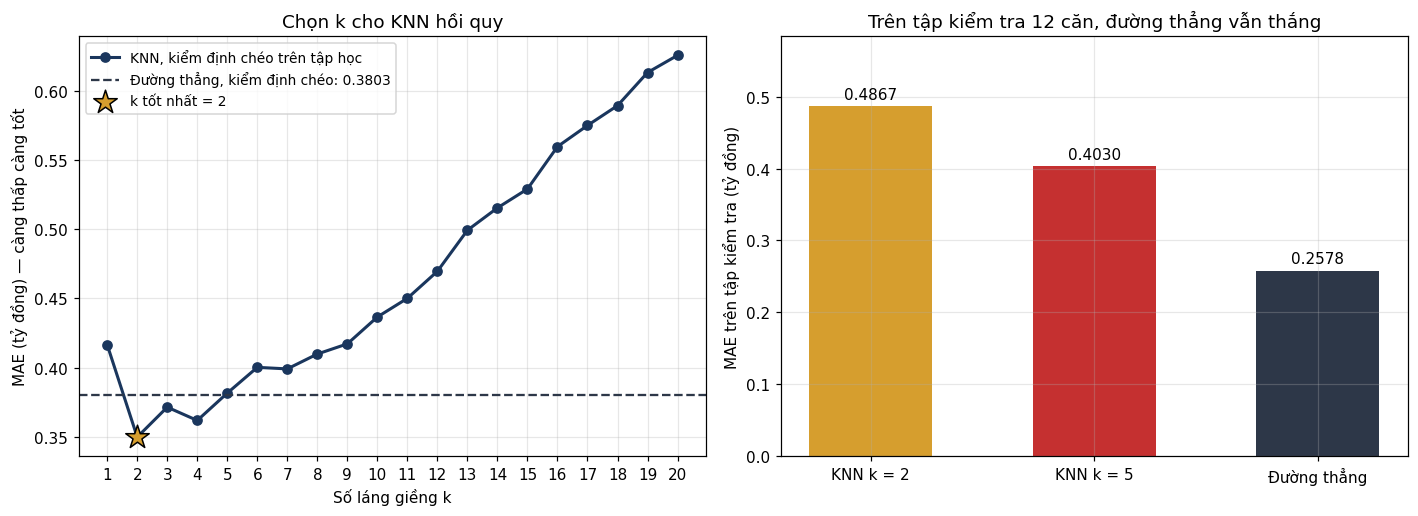

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(list(mae_kiem_dinh.keys()), list(mae_kiem_dinh.values()), "-o", color=MAU_1, linewidth=2,
         label="KNN, kiểm định chéo trên tập học")
ax1.axhline(mae_duong_kd, linestyle="--", color="#2d3748",
            label=f"Đường thẳng, kiểm định chéo: {mae_duong_kd:.4f}")
ax1.scatter([k_tot_nhat], [mae_kiem_dinh[k_tot_nhat]], s=260, marker="*", color="#d69e2e",
            edgecolor="black", zorder=5, label=f"k tốt nhất = {k_tot_nhat}")
ax1.set_xticks(range(1, 21))
ax1.set_xlabel("Số láng giềng k")
ax1.set_ylabel("MAE (tỷ đồng) — càng thấp càng tốt")
ax1.set_title("Chọn k cho KNN hồi quy")
ax1.legend(loc="upper left", fontsize=9)

ten_cot = [f"KNN k = {k_tot_nhat}", "KNN k = 5", "Đường thẳng"]
gia_tri = [mae_knn_tot, mae_knn_5, mae_duong_thang]
cot_ve = ax2.bar(ten_cot, gia_tri, color=["#d69e2e", MAU_0, "#2d3748"], width=0.55)
ax2.bar_label(cot_ve, fmt="%.4f", padding=3)
ax2.set_ylim(0, max(gia_tri) * 1.2)
ax2.set_ylabel("MAE trên tập kiểm tra (tỷ đồng)")
ax2.set_title("Trên tập kiểm tra 12 căn, đường thẳng vẫn thắng")
plt.tight_layout()
luu_hinh("bai5_chon_k_hoi_quy.png")

**Kết quả:** kiểm định chéo chọn **$k = 2$** với MAE trung bình **0.3498** tỷ. Nhưng trên tập kiểm tra, KNN với
$k = 2$ cho MAE **0.4867** tỷ — còn tệ hơn $k = 5$ của Bước 5 (0.4030), và **không vượt được đường thẳng
(0.2578)**.

**Nhận xét:**

1. **Không, KNN không vượt được đường thẳng trên tập kiểm tra**, dù đã chọn $k$ cẩn thận: 0.4867 so với 0.2578,
   KNN sai trung bình gần gấp đôi. Như Bước 5 đã nói, giá nhà tăng gần như thẳng theo diện tích, nên giả định
   của đường thẳng là đúng; KNN phải tự "dò" lại đường đó từ vài láng giềng nên kém chính xác hơn.
2. **Nhưng kiểm định chéo lại nói ngược lại** — và đây là chỗ đáng suy nghĩ nhất. Trên tập học, đường thẳng có
   MAE kiểm định chéo **0.3803**, *thua* KNN với $k = 2$ tới $5$ (0.35 – 0.38). Hai thước đo mâu thuẫn nhau vì
   dữ liệu quá ít: tập học chỉ có 48 căn, mỗi phần kiểm định chéo khoảng 10 căn, còn tập kiểm tra chỉ 12 căn.
   Với cỡ mẫu này, chỉ vài căn "khó đoán" rơi vào phần nào là đủ đảo thứ hạng. Vì thế $k$ tốt nhất theo kiểm định
   chéo ($k = 2$) cũng không tốt nhất trên tập kiểm tra ($k = 5$ của Bước 5 còn tốt hơn), và chênh lệch giữa các
   $k$ nhỏ phần lớn là do may rủi của việc chia. Kết luận đáng tin là ở **xu hướng**: trên dữ liệu gần thẳng
   này, KNN không có lợi thế gì để bù cho việc nó cần nhiều dữ liệu hơn.
3. Đường MAE tăng đều khi $k$ lớn dần: với 48 căn mà lấy trung bình 15–20 láng giềng thì dự đoán bị kéo về giá
   trung bình của cả một khoảng diện tích rộng, đúng kiểu "cẩu thả" ở Bước 3 nhưng cho bài hồi quy.

## Bài tập 6 — Đo thời gian dự đoán

Tạo bộ dữ liệu ngẫu nhiên có 1000, 10000 và 100000 mẫu với 2 đặc trưng bằng
`np.random.default_rng(0).random`. Với mỗi cỡ, đo thời gian `.fit` và thời gian `.predict` cho 1000 mẫu mới
bằng mô đun `time`. Lập bảng kết quả rồi giải thích vì sao KNN được gọi là mô hình học lười.

> Kết quả thời gian khác nhau giữa các máy (và giữa các lần chạy) là chuyện bình thường, chỉ cần so **tương
> đối** giữa các cỡ dữ liệu. Để thấy rõ, ô dưới đo thêm hai thứ để đối chứng: một **KNN tự viết** theo đúng
> cách của Bài tập 1 (tính khoảng cách tới mọi mẫu đã nhớ, không có mẹo tăng tốc nào) và **hồi quy logistic**
> (một mô hình "học chăm"). Mỗi phép đo được chạy thử một lần cho "nóng máy" rồi lấy lần nhanh nhất, để bớt
> nhiễu do máy đang bận việc khác.

In [24]:
"""Bai 6: do thoi gian fit va predict cua KNN theo co du lieu."""

import time

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


class KnnTuViet:
    """KNN tu viet nhu Bai tap 1: fit chi cat du lieu, predict lam het moi viec."""

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_hoc, self.y_hoc = X, y          # "hoc" = ghi nho nguyen van, khong tinh gi ca
        return self

    def predict(self, X_moi):
        du_doan = np.empty(len(X_moi), dtype=int)
        for i, x in enumerate(X_moi):
            binh_phuong_kc = ((self.X_hoc - x) ** 2).sum(axis=1)       # toi MOI mau da nho
            gan_nhat = np.argpartition(binh_phuong_kc, self.k)[:self.k]
            du_doan[i] = np.bincount(self.y_hoc[gan_nhat], minlength=2).argmax()
        return du_doan


bo_sinh_so = np.random.default_rng(0)
mau_moi = bo_sinh_so.random((1000, 2))           # 1000 mau can du doan, dung chung cho moi co


def do_thoi_gian(ham, so_lan=5):
    """Chay thu mot lan cho 'nong may', roi lay lan nhanh nhat (giay) trong so_lan lan."""
    ham()
    cac_lan = []
    for _ in range(so_lan):
        bat_dau = time.perf_counter()
        ham()
        cac_lan.append(time.perf_counter() - bat_dau)
    return min(cac_lan)


cac_mo_hinh_do = [
    ("KNN tu viet", lambda: KnnTuViet(k=5), 2),
    ("KNN scikit-learn", lambda: KNeighborsClassifier(n_neighbors=5), 5),
    ("Hoi quy logistic", lambda: LogisticRegression(), 5),
]

bang_thoi_gian = []
for co_du_lieu in [1000, 10000, 100000]:
    X_ngau_nhien = bo_sinh_so.random((co_du_lieu, 2))
    y_ngau_nhien = (X_ngau_nhien.sum(axis=1) > 1).astype(int)   # nhan theo mot quy tac don gian

    for ten_mo_hinh, tao_mo_hinh, so_lan in cac_mo_hinh_do:
        mo_hinh = tao_mo_hinh()
        giay_fit = do_thoi_gian(lambda: mo_hinh.fit(X_ngau_nhien, y_ngau_nhien), so_lan)
        giay_predict = do_thoi_gian(lambda: mo_hinh.predict(mau_moi), so_lan)
        bang_thoi_gian.append({"co_du_lieu": co_du_lieu, "mo_hinh": ten_mo_hinh,
                               "fit_ms": giay_fit * 1000, "predict_1000_mau_ms": giay_predict * 1000})

bang_thoi_gian = pd.DataFrame(bang_thoi_gian)
pd.set_option("display.width", 140)
print("Thoi gian (mili giay), lay lan nhanh nhat:")
print(bang_thoi_gian.pivot(index="co_du_lieu", columns="mo_hinh",
                           values=["fit_ms", "predict_1000_mau_ms"]).round(3).to_string())
print()

for ten_mo_hinh, _, _ in cac_mo_hinh_do:
    dong = bang_thoi_gian[bang_thoi_gian["mo_hinh"] == ten_mo_hinh].set_index("co_du_lieu")
    print(f"{ten_mo_hinh:17s}: predict cham hon fit "
          + ", ".join(f"{dong.loc[n, 'predict_1000_mau_ms'] / dong.loc[n, 'fit_ms']:9.1f} lan (n={n})"
                      for n in dong.index))
print()
tu_viet = bang_thoi_gian[bang_thoi_gian["mo_hinh"] == "KNN tu viet"].set_index("co_du_lieu")
print("KNN tu viet, du lieu tang 10 lan va 100 lan thi predict cham di: "
      f"{tu_viet.loc[10000, 'predict_1000_mau_ms'] / tu_viet.loc[1000, 'predict_1000_mau_ms']:.1f} lan va "
      f"{tu_viet.loc[100000, 'predict_1000_mau_ms'] / tu_viet.loc[1000, 'predict_1000_mau_ms']:.1f} lan")

Thoi gian (mili giay), lay lan nhanh nhat:
                     fit_ms                              predict_1000_mau_ms                             
mo_hinh    Hoi quy logistic KNN scikit-learn KNN tu viet    Hoi quy logistic KNN scikit-learn KNN tu viet
co_du_lieu                                                                                               
1000                  2.287            0.550       0.001               0.073            2.005      30.692
10000                 9.970            3.699       0.000               0.057            2.273     229.961
100000               64.333           48.007       0.001               0.077            3.606    3638.565

KNN tu viet      : predict cham hon fit   51152.8 lan (n=1000),  766532.5 lan (n=10000), 7277074.6 lan (n=100000)
KNN scikit-learn : predict cham hon fit       3.6 lan (n=1000),       0.6 lan (n=10000),       0.1 lan (n=100000)
Hoi quy logistic : predict cham hon fit       0.0 lan (n=1000),       0.0 lan (n=10000),    

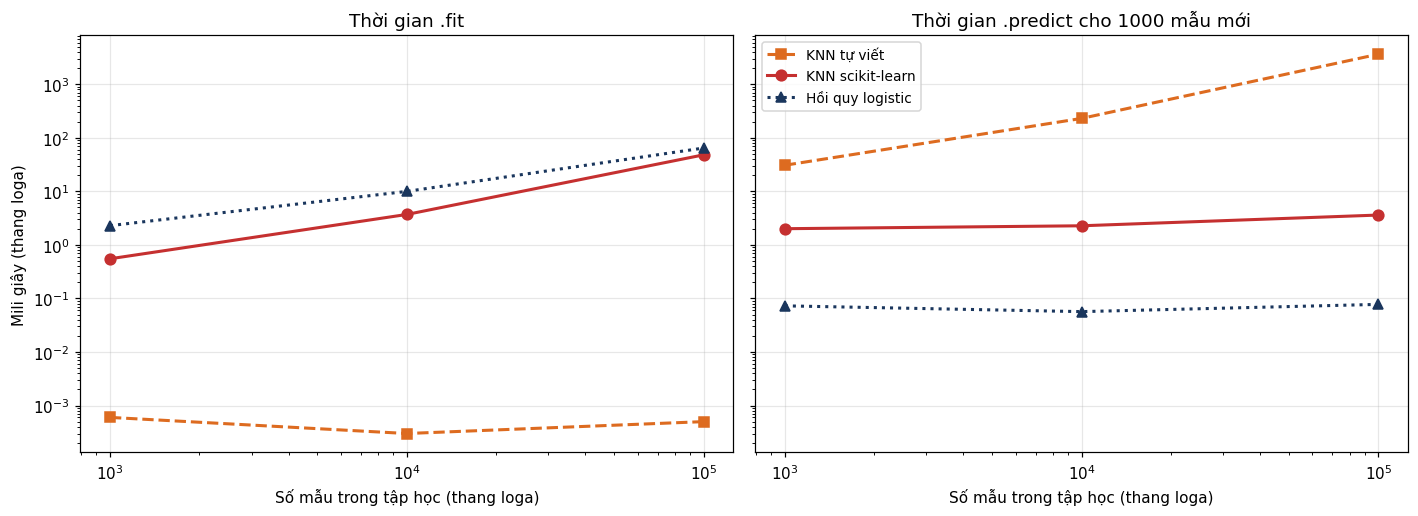

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, cot, tieu_de in [(ax1, "fit_ms", "Thời gian .fit"),
                         (ax2, "predict_1000_mau_ms", "Thời gian .predict cho 1000 mẫu mới")]:
    for ten_mo_hinh, nhan_hien_thi, mau, kieu in [
            ("KNN tu viet", "KNN tự viết", "#dd6b20", "--s"),
            ("KNN scikit-learn", "KNN scikit-learn", MAU_0, "-o"),
            ("Hoi quy logistic", "Hồi quy logistic", MAU_1, ":^")]:
        dong = bang_thoi_gian[bang_thoi_gian["mo_hinh"] == ten_mo_hinh]
        ax.plot(dong["co_du_lieu"], dong[cot], kieu, color=mau, linewidth=2, markersize=7, label=nhan_hien_thi)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Số mẫu trong tập học (thang loga)")
    ax.set_title(tieu_de)
ax1.set_ylabel("Mili giây (thang loga)")
ax2.legend(loc="upper left", fontsize=9)
plt.tight_layout()
luu_hinh("bai6_thoi_gian_hoc_luoi.png")

**Đọc bảng và hình** (con số cụ thể đổi theo máy và theo lần chạy, nhưng hình dạng thì không):

- **KNN tự viết là trường hợp lười "nguyên chất":** `.fit` chỉ tốn vài micro giây ở mọi cỡ dữ liệu — nó chỉ ghi
  nhớ hai mảng, không tính gì cả. Toàn bộ công việc dồn sang `.predict`: mỗi mẫu mới phải tính khoảng cách tới
  **mọi** mẫu đã nhớ, nên dự đoán chậm hơn huấn luyện **hàng chục nghìn lần trở lên**, và **dữ liệu tăng bao
  nhiêu lần thì thời gian dự đoán tăng gần bấy nhiêu lần** (dòng cuối của kết quả, đường cam dốc lên đều ở hình
  bên phải).
- **KNN của scikit-learn** (với dữ liệu ít chiều, nó tự chọn cấu trúc cây *kd-tree*) **bớt lười** đi một chút:
  lúc `.fit` nó bỏ công sắp xếp dữ liệu thành cây — nên thời gian `.fit` tăng theo cỡ dữ liệu — để lúc dự đoán
  chỉ cần đi xuống cây thay vì so với mọi mẫu, nhờ vậy dự đoán nhanh hơn bản tự viết rất nhiều. Đây là mẹo kỹ
  thuật để giảm cái giá của việc học lười, chứ không thay đổi bản chất: mô hình vẫn phải giữ toàn bộ dữ liệu và
  vẫn phải lục lại dữ liệu đó cho mỗi lần dự đoán, nên dự đoán vẫn chậm hơn hồi quy logistic cỡ chục lần trở lên.
- **Hồi quy logistic** thì ngược lại: `.fit` tốn công nhất (phải dò trọng số qua nhiều vòng lặp, và tăng theo cỡ
  dữ liệu), nhưng `.predict` chỉ vài phần mười mili giây và gần như **không phụ thuộc cỡ dữ liệu học** — vì sau
  khi học, mô hình chỉ còn vài con số $w$ và $b$, còn dữ liệu học thì bỏ đi.

**Vì sao KNN được gọi là học lười:** vì nó **hoãn mọi công việc tới lúc bị hỏi**. Lúc "học", KNN không rút ra
quy luật nào, không tính hệ số nào — chỉ ghi nhớ nguyên văn dữ liệu. Lúc dự đoán, nó mới làm hết: tính khoảng
cách, tìm láng giềng, bỏ phiếu — và phải làm lại từ đầu cho **từng** mẫu mới, trên **toàn bộ** dữ liệu đã nhớ.
Hệ quả thực tế: KNN huấn luyện tức thì nhưng dự đoán chậm, tốn bộ nhớ, và càng nhiều dữ liệu thì càng chậm —
ngược hẳn với các mô hình "học chăm" như hồi quy logistic, tốn công lúc học để lúc dùng thật nhanh. Đây là điều
cần cân nhắc khi đưa KNN vào một ứng dụng phải trả lời nhanh trên dữ liệu lớn.

---
## Tổng kết — các con số chính của bài *(Bảng 3)*

| Đại lượng | Giá trị | Ở đâu |
|---|---|---|
| $d(A, B)$ và $d(A, C)$ khi chưa chuẩn hoá | 102.2 và 3000.0 | Bước 1 |
| $d(A, B)$ và $d(A, C)$ khi đã chuẩn hoá | 3.85 và 1.79 | Bước 1 |
| Ba cột, không chuẩn hoá | 0.5333 | Bước 2 |
| Ba cột, có chuẩn hoá | 0.8667 | Bước 2, Bài tập 3 |
| Bỏ cột chi tiêu, có chuẩn hoá | 0.9000 | Bước 2 |
| Mức đoán bừa trên tập kiểm tra | 0.6000 | Bước 2 |
| $k$ tốt nhất theo kiểm định chéo | 13, điểm 0.8667 | Bước 3 |
| Hai vầng trăng, KNN với $k = 13$ | 0.9200 | Bước 3, 4, Bài tập 1 |
| Hai vầng trăng, logistic và Naive Bayes | cùng bằng 0.8533 | Bước 4 |
| Giá nhà, MAE của KNN và của đường thẳng | 0.4030 và 0.2578 | Bước 5 |
| Manhattan: $k$ tốt nhất và accuracy kiểm tra | 27 và 0.9067 | Bài tập 2 |
| Chi tiêu tính bằng triệu đồng, không chuẩn hoá | 0.8667 | Bài tập 3 |
| $k = 101$ phiếu đều / theo khoảng cách | 0.8533 / 0.9067 | Bài tập 4 |
| KNN hồi quy, $k$ tốt nhất và MAE kiểm tra | 2 và 0.4867 | Bài tập 5 |

**Sáu việc sinh viên phải tự làm được sau bài này:**

1. Tự tính khoảng cách Euclid và tự tìm $k$ láng giềng gần nhất bằng numpy.
2. Chỉ ra được vì sao một cột có thang đo lớn làm hỏng KNN, và chữa bằng chuẩn hoá.
3. Dùng `make_pipeline` để gộp chuẩn hoá với mô hình cho đúng cách.
4. Chọn số láng giềng $k$ bằng kiểm định chéo mà không nhìn tập kiểm tra.
5. So sánh KNN với hồi quy logistic và Naive Bayes trên dữ liệu có biên cong.
6. Dùng KNN cho bài toán hồi quy và giải thích vì sao nó không ngoại suy được.

> **Một lời khuyên chung:** với KNN, câu hỏi đầu tiên luôn là *các cột đã cùng thang đo chưa?* Câu hỏi thứ hai
> là *có cột nào không liên quan tới thứ cần đoán không?* Trả lời xong hai câu này thì phần lớn lỗi của KNN đã
> được loại bỏ.